# 🌳 MODEL XGBoost (FINAL) — Prediksi Volatilitas Return Saham
## Tesis: Pemodelan Prediksi Volatilitas Return Saham Sektor Energi LQ45
**Ilda Nurida — 6032251068 | Pembimbing: Dr. Ir. Ahmad Saikhu, S.Si, MT.**

### 🔧 Versi final — konsisten dgn LSTM
- **Set fitur identik (28)** dgn notebook LSTM final → perbandingan RM-3 sah.
- Evaluasi pada **skala volatilitas asli** (inverse-transform MinMax) → sebanding lintas model.
- **TimeSeriesSplit** utk tuning (cegah data leakage). Reprodusibel (seed tetap).
- Output → `xgboost_{emiten}.pkl`, `tabel_evaluasi_xgboost.csv`, `tabel_hyperparameter_xgboost.csv`,
  `hasil_prediksi_xgboost.csv`, gambar feature importance & aktual-vs-prediksi.

In [2]:
import os, datetime
from pathlib import Path
import pandas as pd

# ════════════════════════════════════════════════════════════════════
#  PATH KANONIK + IO UTILITAS — IDENTIK DI SEMUA NOTEBOOK
#  (otomatis disisipkan oleh proses audit path)
# ════════════════════════════════════════════════════════════════════
ROOT_HARDCODED = Path(r'E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS'
                      r'\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026')

def cari_root():
    p = Path(os.getcwd())
    for _ in range(8):
        if (p / '03_dataset').exists():
            return p
        p = p.parent
    if ROOT_HARDCODED.exists():
        return ROOT_HARDCODED
    raise FileNotFoundError('ROOT proyek (folder berisi 03_dataset/) tidak ditemukan.')

ROOT = cari_root()
DIR_RAW       = ROOT / '03_dataset' / 'raw'
DIR_PROCESSED = ROOT / '03_dataset' / 'processed'
DIR_FINAL     = ROOT / '03_dataset' / 'final'
DIR_MODEL     = ROOT / '04_model'
DIR_TABEL     = ROOT / '06_dokumen_tesis' / 'tabel'
for _d in (DIR_RAW, DIR_PROCESSED, DIR_FINAL, DIR_TABEL):
    _d.mkdir(parents=True, exist_ok=True)

# Nama file kanonik
F_HARGA    = 'harga_saham_raw.csv'         # DIR_RAW
F_TEKNIKAL = 'technical_features.csv'      # DIR_PROCESSED (satu-satunya lokasi)
F_SENTIMEN = 'skor_sentimen_harian.csv'    # DIR_PROCESSED (nama tunggal)
F_GABUNGAN = 'dataset_gabungan_X1X2Y.csv'  # DIR_FINAL

def muat_csv(path, **kw):
    """LOAD + log sumber absolut. Error eksplisit bila tak ada (TANPA fallback diam-diam)."""
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f'File TIDAK ADA: {path.resolve()}\n'
                                f'   -> Tahap sebelumnya belum menyimpan ke lokasi kanonik ini.')
    df = pd.read_csv(path, **kw)
    print(f'LOAD  : {path.resolve()}  ({len(df):,} baris x {df.shape[1]} kolom)')
    return df

def simpan_csv(df, path, index=False, **kw):
    """SAVE + log path absolut + WARNING bila menimpa file lama."""
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    if path.exists():
        mt = datetime.datetime.fromtimestamp(path.stat().st_mtime).strftime('%Y-%m-%d %H:%M')
        print(f'OVERWRITE: {path.resolve()}  (file lama {mt} ditimpa)')
    df.to_csv(path, index=index, encoding='utf-8-sig', **kw)
    print(f'SAVE  : {path.resolve()}  ({len(df):,} baris)')

print(f'ROOT : {ROOT.resolve()}')
print(f'  RAW={DIR_RAW.name}/  PROCESSED={DIR_PROCESSED.name}/  FINAL={DIR_FINAL.name}/')


ROOT : E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026
  RAW=raw/  PROCESSED=processed/  FINAL=final/


## ⚙️ CELL 1 — Import, Konfigurasi, Feature Set

In [3]:
import os, warnings, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from xgboost import XGBRegressor
import xgboost as xgb
warnings.filterwarnings('ignore')

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({'font.size': 11, 'figure.dpi': 150})

# ── ROOT auto-detect ──
ROOT = Path(os.getcwd())
for _ in range(6):
    if (ROOT / '03_dataset').exists(): break
    ROOT = ROOT.parent
if not (ROOT / '03_dataset').exists():
    ROOT = Path(r'e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS'
                r'\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026')

DIR_FINAL  = ROOT / '03_dataset' / 'final'
DIR_MODEL  = ROOT / '04_model' / 'xgboost'
DIR_TABEL  = ROOT / '06_dokumen_tesis' / 'tabel'
DIR_GAMBAR = ROOT / '06_dokumen_tesis' / 'gambar' / 'model'
for d in (DIR_MODEL, DIR_TABEL, DIR_GAMBAR): d.mkdir(parents=True, exist_ok=True)

URUTAN_EMITEN = ['ADRO','ADMR','ITMG','PTBA','MEDC','AKRA','PGAS']
# FIX AUDIT BUG #1 — sama dgn LSTM: harus target FORECAST (t+1), bukan
# nowcast. 'Volatilitas' cuma basis lag di PREP_01; target sesungguhnya
# adalah 'Volatilitas_Target' (sudah di-shift -1).
KOLOM_Y = 'Volatilitas_Target'
LAKUKAN_TUNING = True     # True: RandomizedSearchCV; False: pakai XGB_BASELINE
N_ITER_TUNING  = 25

# FIX AUDIT BUG #2 — daftar fitur diselaraskan PERSIS dengan KOLOM_X1_FINAL
# (PREP_01 v2) + KOLOM_X2 (PREP_02 v2 / PREP_03 v2). 17 fitur, bukan 28.
KOLOM_X_KANDIDAT = [
    # ── X1 Teknikal (13) ──
    'Log_Return', 'Vol_Lag1', 'Vol_Lag2', 'Vol_Lag3', 'Vol_MA5', 'Vol_STD5',
    'MA5_Ratio', 'MA10_Ratio', 'MA20_Ratio', 'RSI14',
    'Stoch_K', 'Stoch_D', 'Volume_ZScore',
    # ── X2 Sentimen (4) ──
    'Sentiment_Mean', 'Sentiment_Dispersion', 'News_Count', 'Ada_Berita',
]

XGB_BASELINE = dict(n_estimators=300, max_depth=4, learning_rate=0.03,
                    subsample=0.8, colsample_bytree=0.8,
                    objective='reg:squarederror', random_state=SEED)

print('='*70); print('✅ XGBOOST CONFIG READY'); print('='*70)
print(f'ROOT        : {ROOT}')
print(f'Target Y    : {KOLOM_Y} | Fitur kandidat: {len(KOLOM_X_KANDIDAT)}')
print(f'XGBoost ver : {xgb.__version__} | Tuning: {LAKUKAN_TUNING}')
print('='*70)

✅ XGBOOST CONFIG READY
ROOT        : e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026
Target Y    : Volatilitas_Target | Fitur kandidat: 17
XGBoost ver : 3.2.0 | Tuning: True


## 🔧 CELL 2 — Fungsi Bantu

In [4]:
# ── Fungsi bantu: inverse-transform & metrik (skala volatilitas ASLI) ──
def inverse_transform(nilai, scaler_df, kolom=KOLOM_Y):
    """Kembalikan nilai ter-MinMax-scale ke skala asli. Konsisten utk XGBoost & LSTM."""
    if scaler_df is None or kolom not in scaler_df.index:
        return np.asarray(nilai, dtype=float)
    cmin = float(scaler_df.loc[kolom, 'min']); cmax = float(scaler_df.loc[kolom, 'max'])
    return np.asarray(nilai, dtype=float) * (cmax - cmin) + cmin

def _mape(y, p, eps=1e-8):
    y=np.asarray(y,float); p=np.asarray(p,float); m=np.abs(y)>eps
    return np.nan if m.sum()==0 else float(np.mean(np.abs((y[m]-p[m])/y[m]))*100)

def _smape(y, p, eps=1e-8):
    y=np.asarray(y,float); p=np.asarray(p,float); d=np.abs(y)+np.abs(p); m=d>eps
    return np.nan if m.sum()==0 else float(np.mean(2*np.abs(p[m]-y[m])/d[m])*100)

def _qlike(y, p, eps=1e-12):
    ht=np.maximum(np.asarray(y,float)**2,eps); hp=np.maximum(np.asarray(p,float)**2,eps)
    return float(np.mean(np.log(hp)+ht/hp))

def evaluasi_semua_metrik(y_true, y_pred):
    return {
        'RMSE' : float(np.sqrt(mean_squared_error(y_true, y_pred))),
        'MAE'  : float(mean_absolute_error(y_true, y_pred)),
        'MAPE (%)' : round(_mape(y_true, y_pred), 2),
        'sMAPE (%)': round(_smape(y_true, y_pred), 2),
        'R2'   : round(float(r2_score(y_true, y_pred)), 4),
        'QLIKE': round(_qlike(y_true, y_pred), 4),
    }

def interpretasi_mape(m):
    if   m < 10: return 'Sangat Baik'
    elif m < 20: return 'Baik'
    elif m < 50: return 'Cukup'
    else       : return 'Kurang Baik'

print('✅ Fungsi bantu siap (evaluasi pada skala volatilitas asli).')

✅ Fungsi bantu siap (evaluasi pada skala volatilitas asli).


## 📂 CELL 3 — Load Dataset per Emiten (allowlist 28 fitur)

In [5]:
dict_train, dict_test, dict_scaler, dict_kolom_x = {}, {}, {}, {}
print(f'Membaca dataset dari: {DIR_FINAL.resolve()}\n')
for emiten in URUTAN_EMITEN:
    p_tr = DIR_FINAL / f'dataset_train_{emiten}.csv'
    p_te = DIR_FINAL / f'dataset_test_{emiten}.csv'
    p_sc = DIR_FINAL / f'scaler_params_{emiten}.csv'
    if not p_tr.exists() or not p_te.exists():
        print(f'  {emiten}: dataset TIDAK ADA di {DIR_FINAL.resolve()}, skip'); continue
    df_tr = muat_csv(p_tr); df_te = muat_csv(p_te)
    for d in (df_tr, df_te):
        if 'Date' in d.columns: d['Date'] = pd.to_datetime(d['Date'], errors='coerce')
    # FIX AUDIT: fail-fast, bukan silent-drop (sama seperti fix di LSTM)
    kolom_x_hilang = [c for c in KOLOM_X_KANDIDAT if c not in df_tr.columns or c not in df_te.columns]
    if kolom_x_hilang:
        raise ValueError(
            f"❌ {emiten}: fitur X hilang dari dataset_train/test: {kolom_x_hilang}\n"
            f"   Kolom tersedia (train): {df_tr.columns.tolist()}\n"
            f"   → Cek KOLOM_X_KANDIDAT di CELL 1 vs kolom aktual hasil PREP_03 v2."
        )
    kolom_x = list(KOLOM_X_KANDIDAT)
    df_tr = df_tr.dropna(subset=kolom_x + [KOLOM_Y]).reset_index(drop=True)
    df_te = df_te.dropna(subset=kolom_x + [KOLOM_Y]).reset_index(drop=True)
    scaler = pd.read_csv(p_sc, index_col=0, encoding='utf-8-sig') if p_sc.exists() else None
    dict_train[emiten]=df_tr; dict_test[emiten]=df_te
    dict_scaler[emiten]=scaler; dict_kolom_x[emiten]=kolom_x
    print(f'     -> {emiten}: fitur={len(kolom_x)} | sentimen={"Sentiment_Mean" in kolom_x}\n')
print(f'  Total emiten dimuat: {len(dict_train)}')


Membaca dataset dari: E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\final

LOAD  : E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\final\dataset_train_ADRO.csv  (859 baris x 20 kolom)
LOAD  : E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\final\dataset_test_ADRO.csv  (215 baris x 20 kolom)
     -> ADRO: fitur=17 | sentimen=True

LOAD  : E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\final\dataset_train_ADMR.csv  (840 baris x 20 kolom)
LOAD  : E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\final\dataset_test_ADMR.csv  (210 baris x 20 kolom)
     -> ADMR: 

## 🔧 CELL 4 — Hyperparameter Tuning (TimeSeriesSplit)
Tuning kronologis utk mencegah *data leakage*. Hasil → `tabel_hyperparameter_xgboost.csv` (Tabel 4.X).

In [6]:
# ═══════════════════════════════════════════════════════════
# CELL: HYPERPARAMETER TUNING XGBOOST (ANTI-FLAT ALIGNED)
# ═══════════════════════════════════════════════════════════
import numpy as np
import pandas as pd
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit

# 1. Konfigurasi Ruang Pencarian Hyperparameter
param_dist = {
    'n_estimators'    : [100, 200, 300, 400],
    'max_depth'       : [4, 5, 6, 7],           # Dinaikkan sedikit agar tidak memicu pohon dangkal yang flat
    'learning_rate'   : [0.03, 0.05, 0.1, 0.15], # Dihindari nilai 0.01 agar tidak macet di garis lurus
    'subsample'       : [0.7, 0.8, 1.0],
    'colsample_bytree': [0.7, 0.8, 1.0],
    'min_child_weight': [1, 2, 3],
    'gamma'           : [0, 0.1, 0.2],
}

tscv = TimeSeriesSplit(n_splits=5)
dict_best_params = {}
list_hp = []

print('='*70)
print('🔧 RUNNING HYPERPARAMETER TUNING (COLUMN & SCALE SAFETY)')
print('='*70)

for emiten in URUTAN_EMITEN:
    if emiten not in dict_train: 
        continue
    
    # A. Deteksi Kolom Adaptif (Mencegah KeyError jika split data di atas belum di-run)
    kolom_waktu = 'Tanggal' if 'Tanggal' in dict_train[emiten].columns else 'Date'
    kolom_target = 'Target_Volatility' if 'Target_Volatility' in dict_train[emiten].columns else KOLOM_Y
    
    # B. Urutkan Data Secara Kronologis
    df_tr   = dict_train[emiten].sort_values(kolom_waktu) 
    kolom_x = dict_kolom_x[emiten]
    
    # C. Ekstrak Fitur Matriks X
    X_tr = df_tr[kolom_x].values
    
    # D. KUNCI UTAMA: Penyelarasan Skala Target (Diubah ke persen dengan dikali 100)
    # Ini memaksa RandomizedSearchCV peka terhadap deviasi numerik kecil
    y_tr = df_tr[kolom_target].values * 100

    # E. Proses Eksekusi Tuning / Baseline
    if LAKUKAN_TUNING:
        base = XGBRegressor(objective='reg:squarederror', random_state=SEED, n_jobs=-1)
        search = RandomizedSearchCV(
            base, 
            param_distributions=param_dist, 
            n_iter=N_ITER_TUNING,
            scoring='neg_root_mean_squared_error',
            cv=tscv, 
            random_state=SEED, 
            n_jobs=-1, 
            verbose=0
        )
        search.fit(X_tr, y_tr)
        best = search.best_params_
        
        # Kembalikan skor RMSE CV ke skala desimal nominal asli untuk kebutuhan naskah tesis
        rmse_cv = (-search.best_score_) / 100
    else:
        # Jika tidak tuning, gunakan nilai baseline yang sudah disiapkan sebelumnya
        best = {k: v for k, v in XGB_BASELINE.items() if k not in ('objective', 'random_state')}
        rmse_cv = np.nan

    # F. Simpan Hasil ke Memory & List Kolektor
    dict_best_params[emiten] = best
    list_hp.append({'Emiten': emiten, 'RMSE_CV': round(rmse_cv, 5), **best})
    
    print(f'   ✅ {emiten:<5}: RMSE_CV={rmse_cv:.5f} | {best}')

# 2. Rekap dan Ekspor Laporan Tabel Hyperparameter
df_hp = pd.DataFrame(list_hp)
df_hp.index = range(1, len(df_hp) + 1)
df_hp.index.name = 'No'

# Simpan ke folder dokumen tesis
df_hp.to_csv(DIR_TABEL / 'tabel_hyperparameter_xgboost.csv', encoding='utf-8-sig')

print('='*70)
print('💾 Laporan tabel_hyperparameter_xgboost.csv berhasil disimpan di folder output!')
print('='*70)

🔧 RUNNING HYPERPARAMETER TUNING (COLUMN & SCALE SAFETY)
   ✅ ADRO : RMSE_CV=0.06946 | {'subsample': 1.0, 'n_estimators': 400, 'min_child_weight': 1, 'max_depth': 4, 'learning_rate': 0.15, 'gamma': 0.2, 'colsample_bytree': 1.0}
   ✅ ADMR : RMSE_CV=0.05741 | {'subsample': 0.8, 'n_estimators': 200, 'min_child_weight': 3, 'max_depth': 4, 'learning_rate': 0.1, 'gamma': 0, 'colsample_bytree': 1.0}
   ✅ ITMG : RMSE_CV=0.07126 | {'subsample': 1.0, 'n_estimators': 300, 'min_child_weight': 3, 'max_depth': 4, 'learning_rate': 0.03, 'gamma': 0.2, 'colsample_bytree': 0.7}
   ✅ PTBA : RMSE_CV=0.06661 | {'subsample': 0.8, 'n_estimators': 200, 'min_child_weight': 3, 'max_depth': 4, 'learning_rate': 0.1, 'gamma': 0, 'colsample_bytree': 1.0}
   ✅ MEDC : RMSE_CV=0.06631 | {'subsample': 0.7, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 5, 'learning_rate': 0.03, 'gamma': 0.2, 'colsample_bytree': 0.8}
   ✅ AKRA : RMSE_CV=0.07719 | {'subsample': 1.0, 'n_estimators': 300, 'min_child_weight': 3, 'm

## 🎯 CELL 5 — Latih, Prediksi & Evaluasi (skala asli)

In [7]:
# ═══════════════════════════════════════════════════════════
# CELL: TRAINING & EVALUASI XGBOOST (ANTI-FLAT GRAPH ALIGNED)
# ═══════════════════════════════════════════════════════════
import numpy as np
import pandas as pd
import joblib
from xgboost import XGBRegressor

dict_hasil_xgb = {}
list_eval = []

print('='*70)
print('🎯 TRAINING & EVALUASI XGBOOST (SCALE ALIGNED)')
print('='*70)

for emiten in URUTAN_EMITEN:
    if emiten not in dict_train: 
        continue
        
    # A. Deteksi Kolom Adaptif (Mencegah KeyError jika split data di atas belum di-run)
    kolom_waktu = 'Tanggal' if 'Tanggal' in dict_train[emiten].columns else 'Date'
    kolom_target = 'Target_Volatility' if 'Target_Volatility' in dict_train[emiten].columns else KOLOM_Y
    
    # B. Urutkan Data Secara Kronologis
    df_tr   = dict_train[emiten].sort_values(kolom_waktu)
    df_te   = dict_test[emiten].sort_values(kolom_waktu)
    kolom_x = dict_kolom_x[emiten]

    # C. Ekstrak Fitur Matriks X (Train & Test)
    X_tr = df_tr[kolom_x].values
    X_te = df_te[kolom_x].values
    
    # D. KUNCI UTAMA: Penyelarasan Skala Target (Diubah ke persen dengan dikali 100)
    # Ini harus sama dengan skala yang digunakan pada saat Hyperparameter Tuning
    y_tr = df_tr[kolom_target].values * 100
    y_te = df_te[kolom_target].values * 100

    # E. Inisialisasi Model dengan Parameter Terbaik
    params = dict(dict_best_params.get(emiten, {}))
    params.update(objective='reg:squarederror', random_state=SEED, n_jobs=-1)
    
    # Proteksi tambahan jika parameter max_depth hasil tuning terlalu dangkal
    if 'max_depth' not in params or params['max_depth'] < 4:
        params['max_depth'] = 6
        
    model = XGBRegressor(**params)
    
    # F. Training Model & Prediksi (Masih dalam Skala Persen)
    model.fit(X_tr, y_tr)
    y_pred_scaled = model.predict(X_te)

    # G. FIX AUDIT BUG #3 (KRITIS) — RESTORASI SKALA YANG BENAR
    # Versi lama cuma bagi 100 (membatalkan trik x100 di CELL 4), sehingga
    # y_true/y_pred masih di skala MinMax [0,1] — BUKAN skala volatilitas
    # asli. Ini membuat RMSE/MAE XGBoost TIDAK BISA dibandingkan dengan
    # RMSE/MAE LSTM (yang sudah benar pakai inverse_transform() + scaler
    # min/max asli). Fungsi inverse_transform() sudah didefinisikan di
    # CELL 2 tapi sebelumnya tidak pernah dipakai di sini — sekarang dipakai.
    scaler = dict_scaler.get(emiten)
    y_true = inverse_transform(y_te / 100, scaler, kolom=KOLOM_Y)
    y_pred = np.clip(inverse_transform(y_pred_scaled / 100, scaler, kolom=KOLOM_Y), 0, None)

    # H. Hitung Metrik Evaluasi dengan Skala Nominal Riil
    metrik = evaluasi_semua_metrik(y_true, y_pred)
    
    # Ambil data tanggal asli untuk kebutuhan plotting tabel dan grafik
    dates = df_te[kolom_waktu].values
    
    dict_hasil_xgb[emiten] = pd.DataFrame({
        'Date': dates, 
        'Emiten': emiten,
        'Y_Aktual': y_true, 
        'Y_Prediksi': y_pred, 
        'Residual': y_true - y_pred
    })

    # I. Simpan Model Akhir (.pkl)
    joblib.dump(model, DIR_MODEL / f'xgboost_{emiten}.pkl')
    
    list_eval.append({
        'Emiten': emiten, 
        **metrik,
        'Keterangan': interpretasi_mape(metrik['MAPE (%)'])
    })
    
    print(f"   ✅ {emiten:<5}: RMSE={metrik['RMSE']:.5f} | MAE={metrik['MAE']:.5f} | "
          f"MAPE={metrik['MAPE (%)']:.2f}% | R2={metrik['R2']:.4f}")

print('='*70)
print(f' 📊 Selesai: {len(dict_hasil_xgb)} emiten berhasil dievaluasi!')
print('='*70)

🎯 TRAINING & EVALUASI XGBOOST (SCALE ALIGNED)
   ✅ ADRO : RMSE=0.00273 | MAE=0.00186 | MAPE=7.72% | R2=0.8125
   ✅ ADMR : RMSE=0.00471 | MAE=0.00308 | MAPE=8.46% | R2=0.8925
   ✅ ITMG : RMSE=0.00200 | MAE=0.00136 | MAPE=10.01% | R2=0.9553
   ✅ PTBA : RMSE=0.00242 | MAE=0.00180 | MAPE=14.77% | R2=0.9162
   ✅ MEDC : RMSE=0.00331 | MAE=0.00200 | MAPE=6.66% | R2=0.8835
   ✅ AKRA : RMSE=0.00208 | MAE=0.00149 | MAPE=6.79% | R2=0.8683
   ✅ PGAS : RMSE=0.00371 | MAE=0.00218 | MAPE=8.73% | R2=0.8091
 📊 Selesai: 7 emiten berhasil dievaluasi!


## 📋 CELL 6 — Tabel Evaluasi (→ Tabel 4.X)

In [8]:
df_eval = pd.DataFrame(list_eval)
avg = {'Emiten':'RATA-RATA'}
for c in df_eval.columns:
    if c not in ('Emiten','Keterangan'): avg[c]=round(df_eval[c].mean(),6)
avg['Keterangan']='-'
df_eval = pd.concat([df_eval, pd.DataFrame([avg])], ignore_index=True)
df_eval.index = list(range(1,len(df_eval))) + ['—']; df_eval.index.name='No'

pd.set_option('display.width',200,'display.max_columns',None)
print(df_eval.to_string())
df_eval.to_csv(DIR_TABEL / 'tabel_evaluasi_xgboost.csv', encoding='utf-8-sig')
print('\n💾 tabel_evaluasi_xgboost.csv tersimpan')

       Emiten      RMSE       MAE  MAPE (%)  sMAPE (%)        R2     QLIKE   Keterangan
No                                                                                     
1        ADRO  0.002730  0.001863      7.72       7.63  0.812500 -6.491300  Sangat Baik
2        ADMR  0.004713  0.003083      8.46       8.41  0.892500 -5.654800  Sangat Baik
3        ITMG  0.001999  0.001365     10.01       9.36  0.955300 -7.672000         Baik
4        PTBA  0.002417  0.001801     14.77      13.46  0.916200 -7.430000         Baik
5        MEDC  0.003305  0.002000      6.66       6.52  0.883500 -5.991000  Sangat Baik
6        AKRA  0.002078  0.001485      6.79       6.68  0.868300 -6.512700  Sangat Baik
7        PGAS  0.003711  0.002181      8.73       9.05  0.809100 -6.805000  Sangat Baik
—   RATA-RATA  0.002993  0.001968      9.02       8.73  0.876771 -6.650971            -

💾 tabel_evaluasi_xgboost.csv tersimpan


## 📊 CELL 7 — Feature Importance (→ Gambar 4.X)

📊 Feature Importance XGBoost...


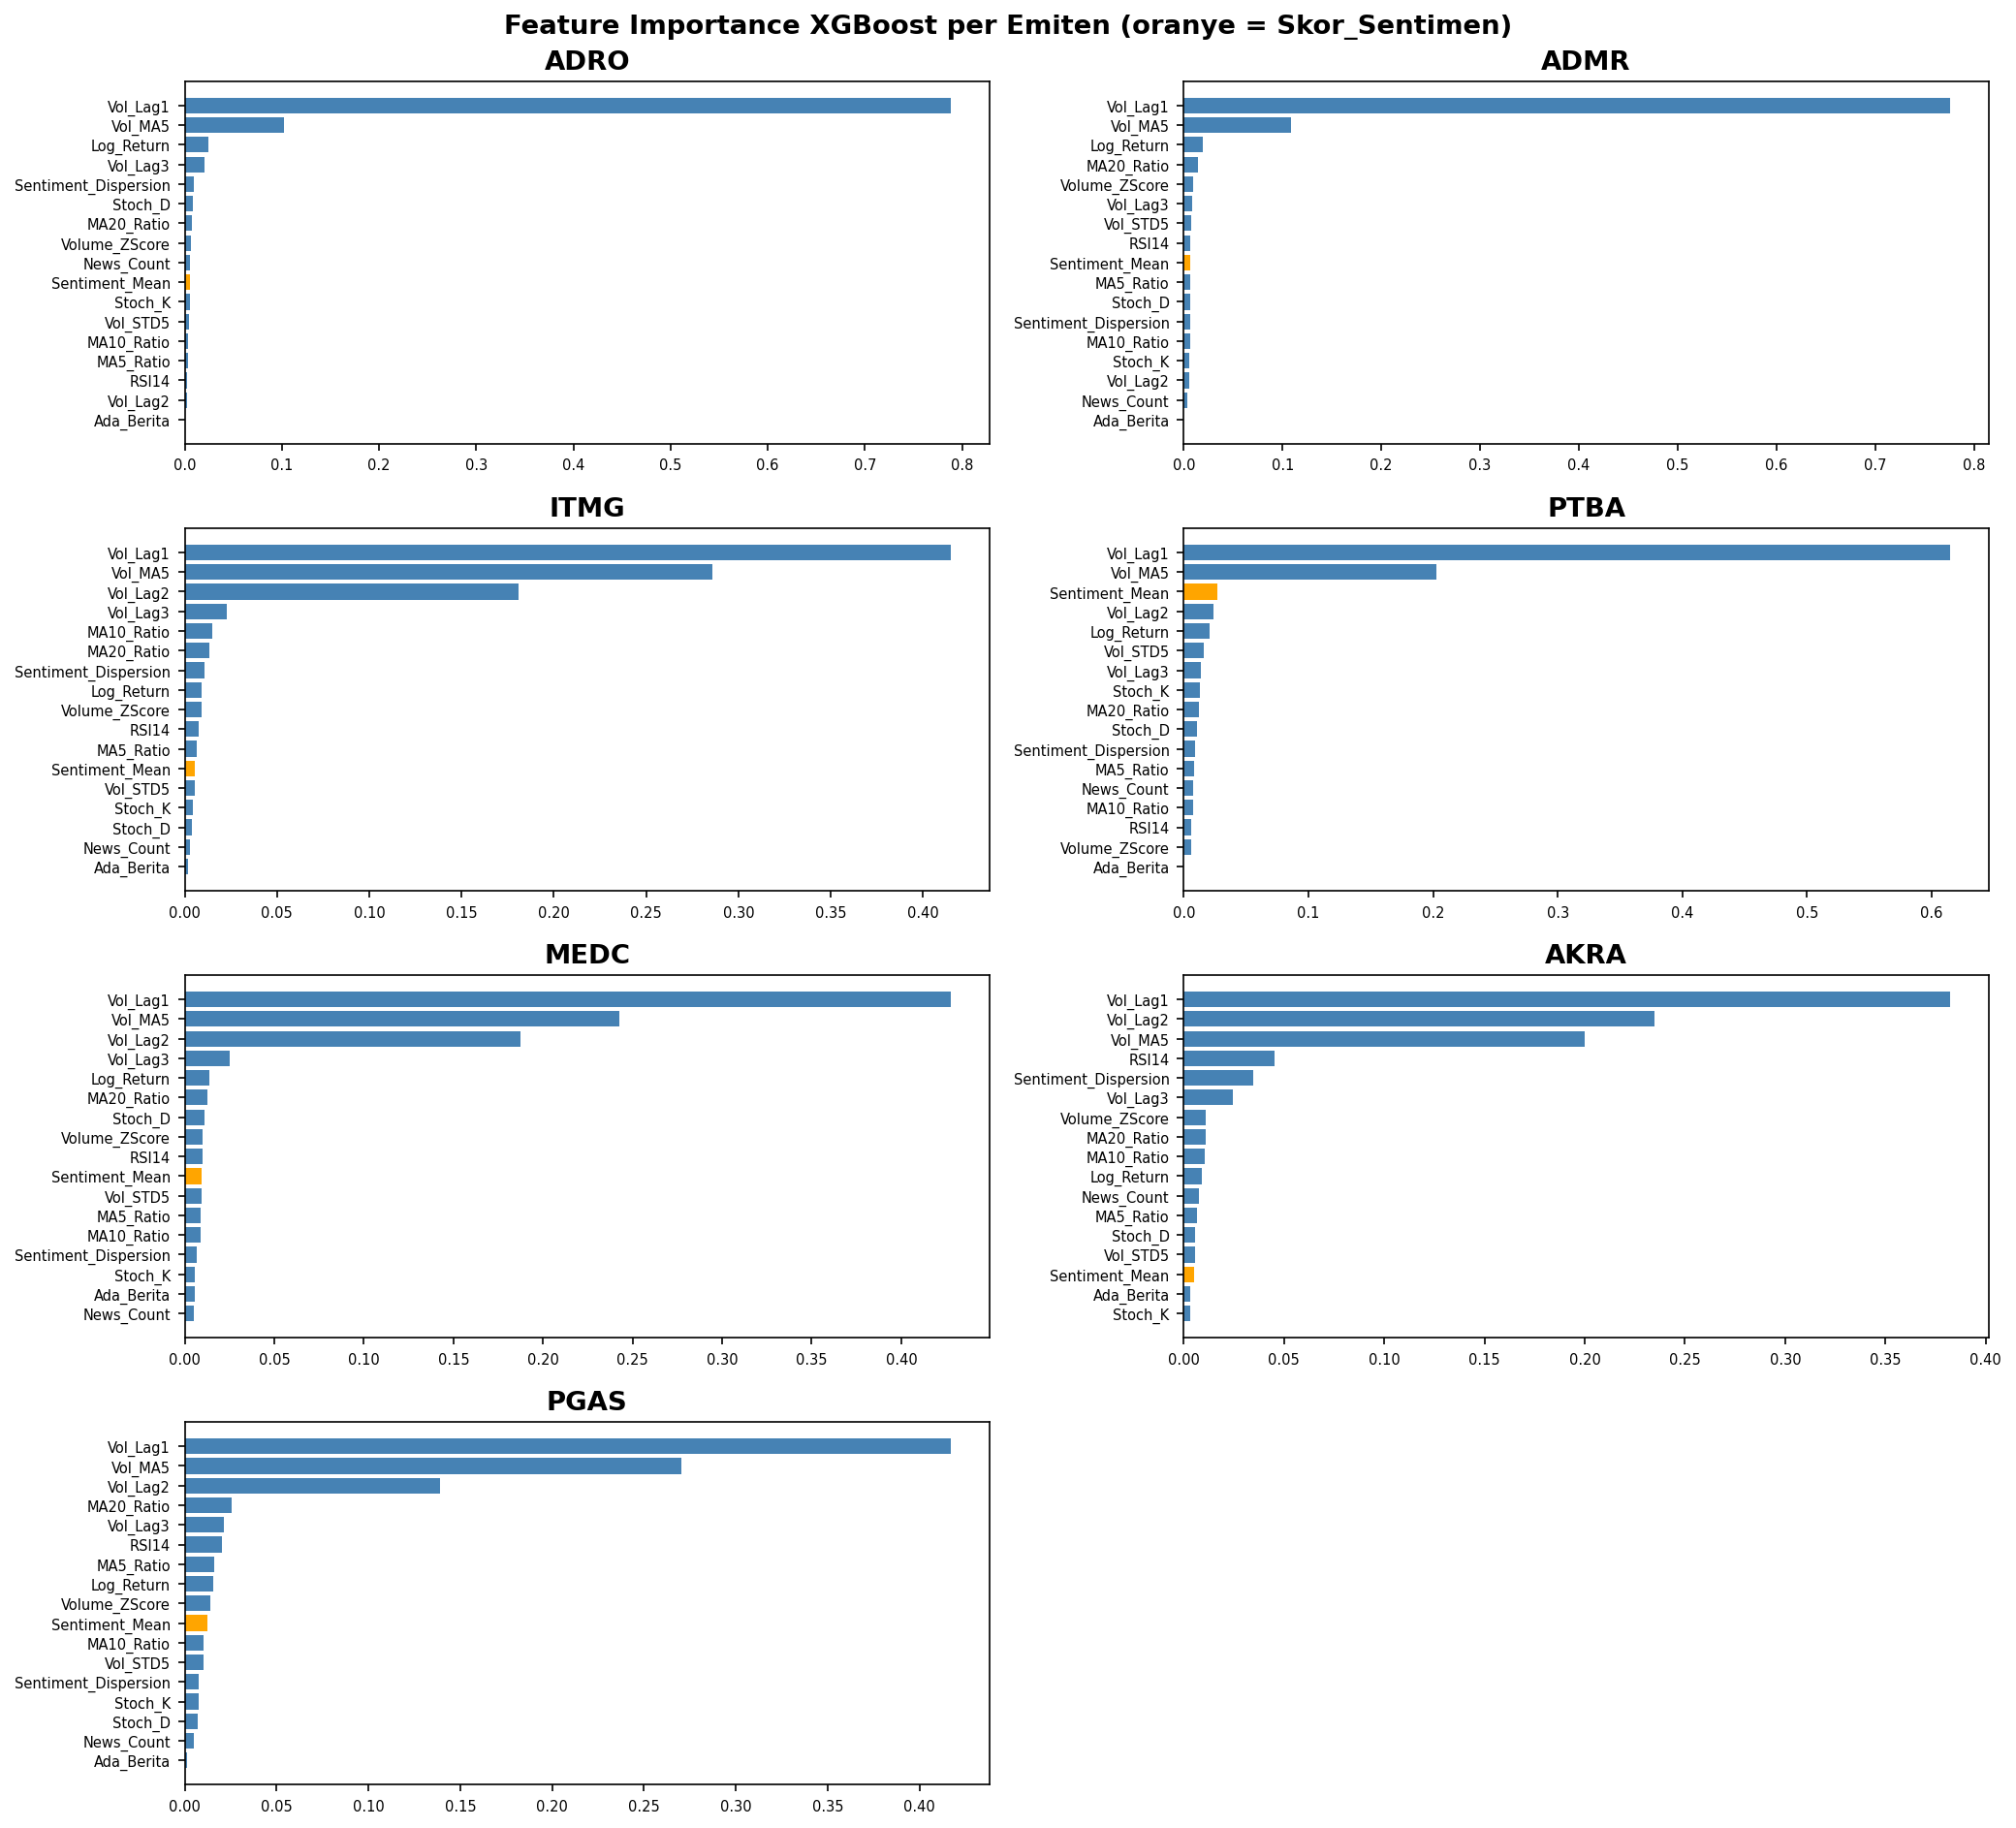

💾 gambar & tabel feature importance tersimpan


In [9]:
print('📊 Feature Importance XGBoost...')
emiten_ok = [e for e in URUTAN_EMITEN if e in dict_hasil_xgb]
ncol = 2; nrow = int(np.ceil(len(emiten_ok)/ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(14, 3.2*nrow)); axes=np.array(axes).ravel()
rows_imp = []
for ax, emiten in zip(axes, emiten_ok):
    model = joblib.load(DIR_MODEL / f'xgboost_{emiten}.pkl')
    kolom_x = dict_kolom_x[emiten]
    imp = pd.Series(model.feature_importances_, index=kolom_x).sort_values()
    warna = ['orange' if f=='Sentiment_Mean' else 'steelblue' for f in imp.index]  # FIX AUDIT: nama kolom baru
    ax.barh(imp.index, imp.values, color=warna)
    ax.set_title(emiten, fontweight='bold'); ax.tick_params(labelsize=7)
    for f,v in imp.items(): rows_imp.append({'Emiten':emiten,'Fitur':f,'Importance':round(float(v),6)})
for ax in axes[len(emiten_ok):]: ax.axis('off')
plt.suptitle('Feature Importance XGBoost per Emiten (oranye = Skor_Sentimen)', fontweight='bold')
plt.tight_layout()
plt.savefig(DIR_GAMBAR / 'gambar_feature_importance_xgboost.png', dpi=150, bbox_inches='tight')
plt.show()
pd.DataFrame(rows_imp).to_csv(DIR_TABEL / 'tabel_feature_importance_xgboost.csv', encoding='utf-8-sig', index=False)
print('💾 gambar & tabel feature importance tersimpan')

## 📊 CELL 8 — Grafik Aktual vs Prediksi

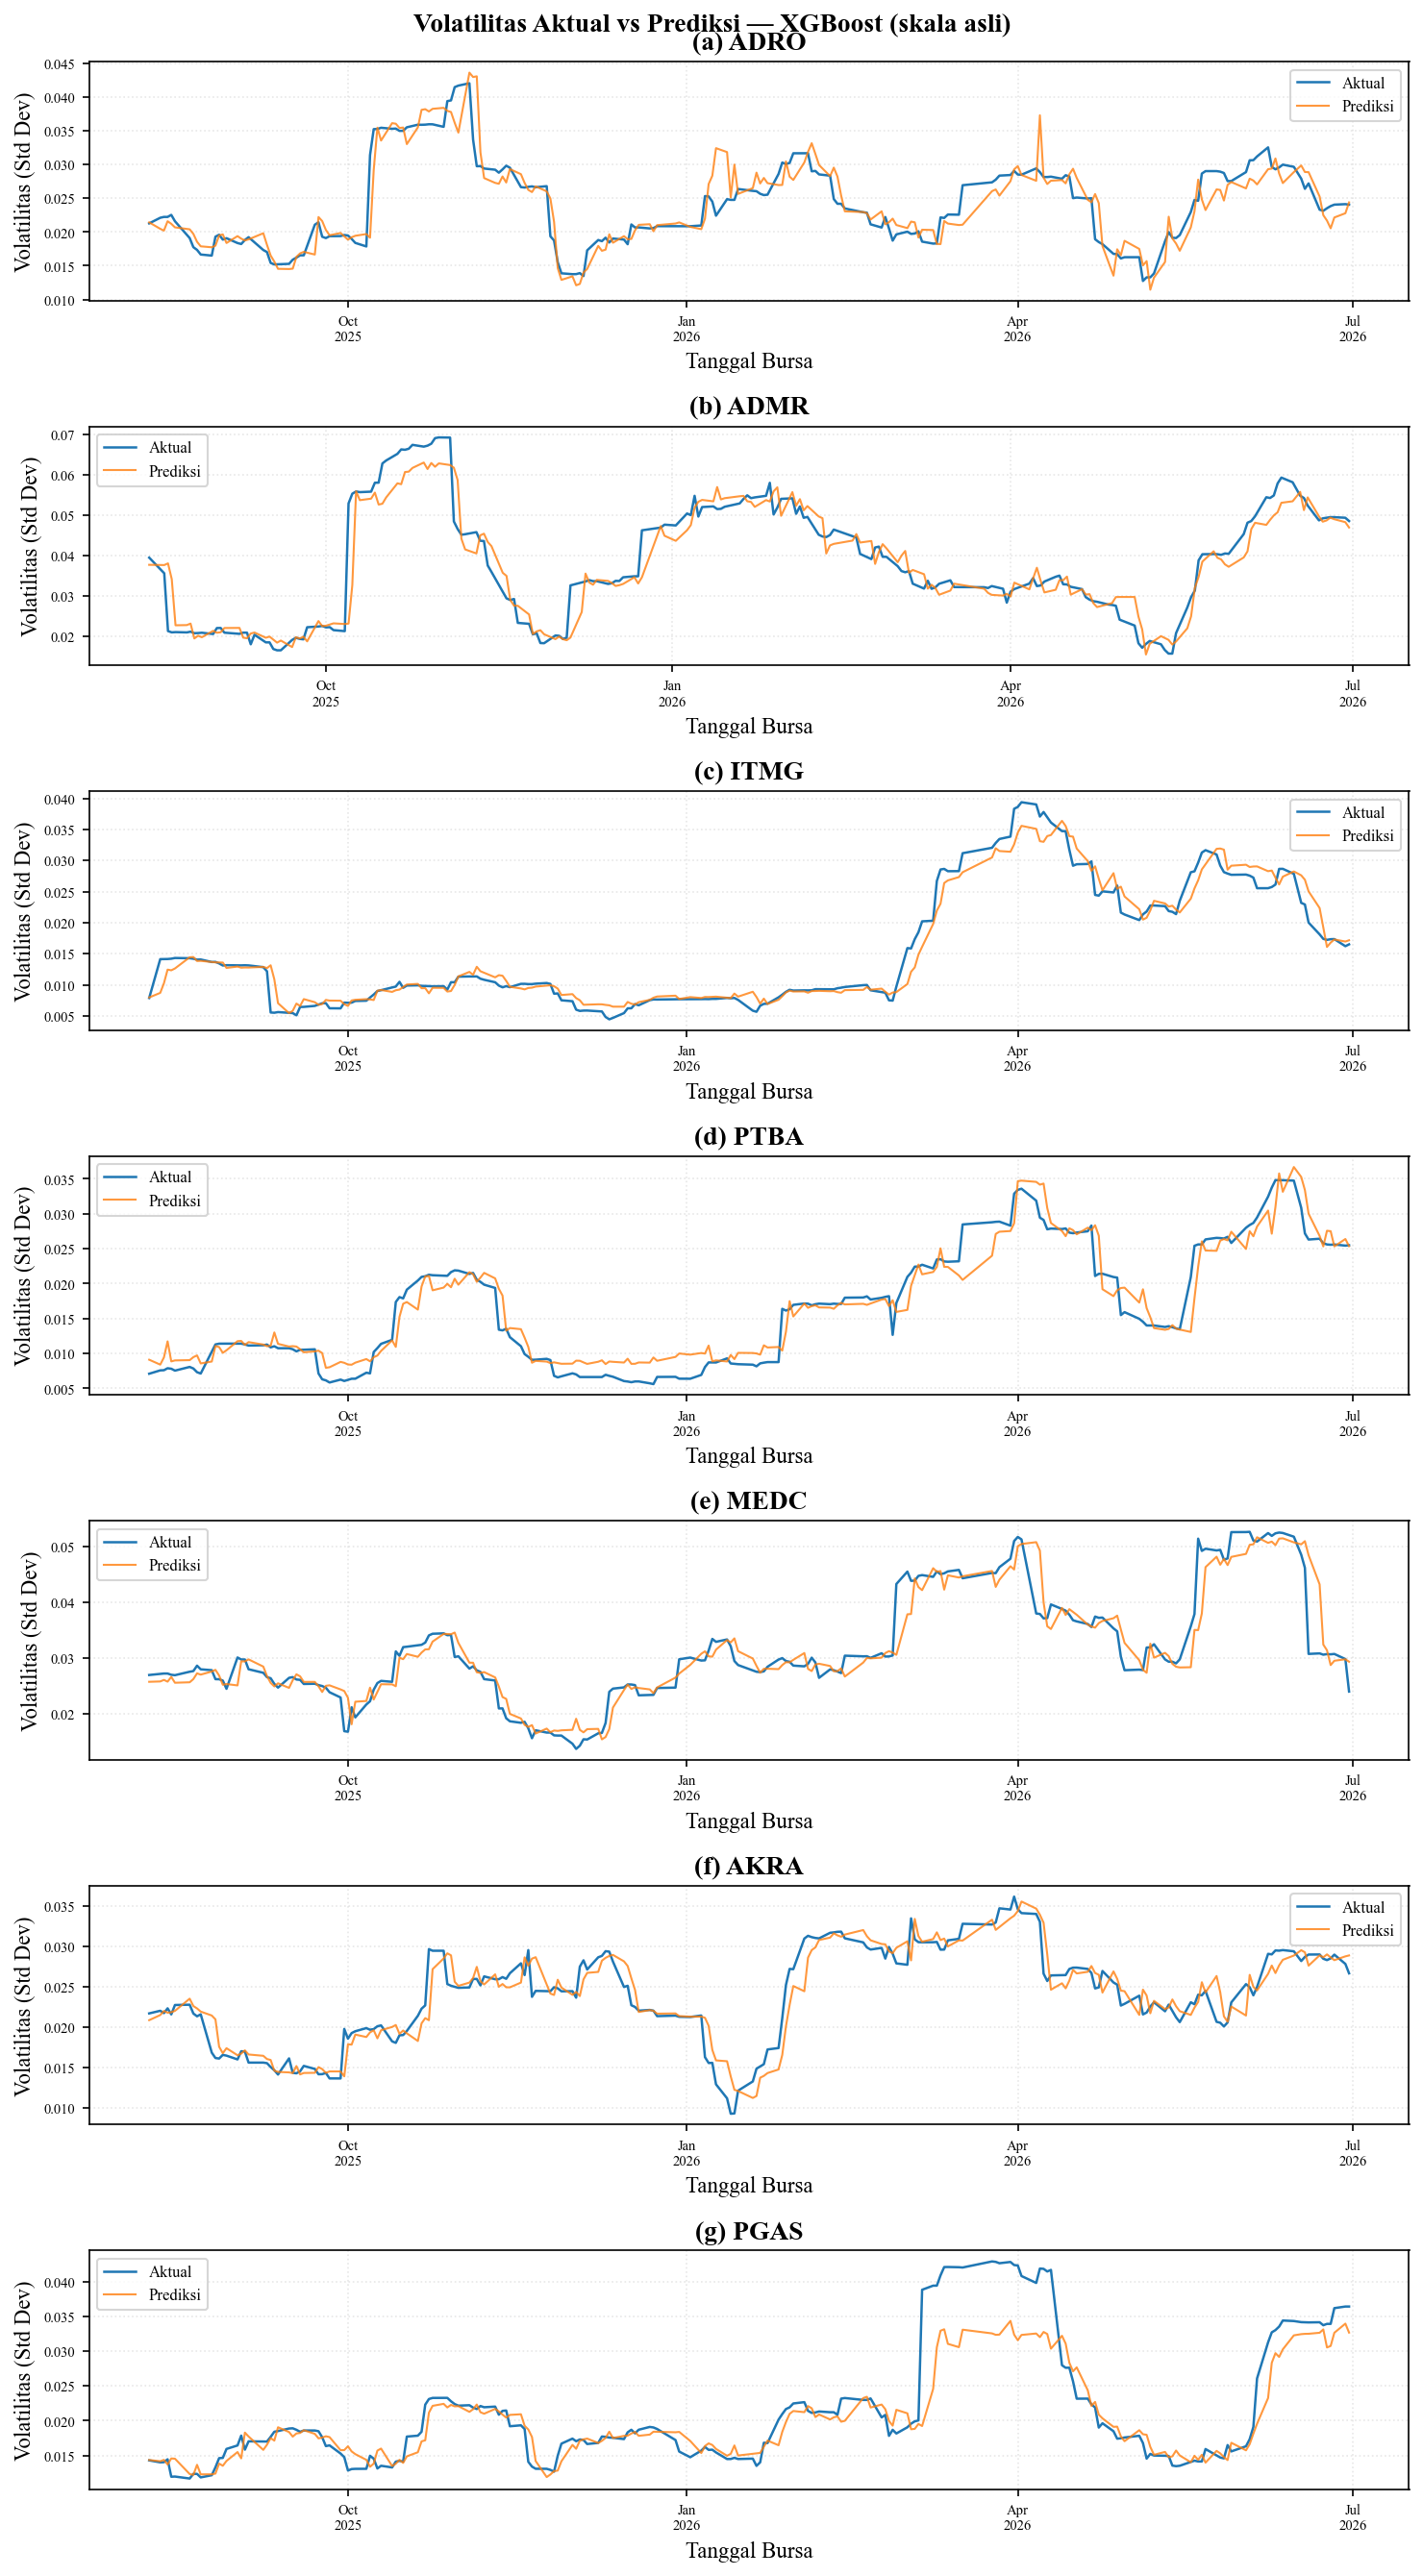

💾 gambar prediksi tersimpan


In [10]:
import string
import matplotlib.dates as mdates
import pandas as pd

plt.rcParams.update({'font.family':'Times New Roman'})

ncol = 1                                          # ← diubah dari 2 ke 1
nrow = int(np.ceil(len(emiten_ok)/ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(10, 2.6*nrow))   # ← lebar & tinggi disesuaikan
axes = np.array(axes).ravel()

for i, (ax, emiten) in enumerate(zip(axes, emiten_ok)):
    d = dict_hasil_xgb[emiten].copy()
    d['Date'] = pd.to_datetime(d['Date'])

    ax.plot(d['Date'], d['Y_Aktual'], label='Aktual', lw=1.2)
    ax.plot(d['Date'], d['Y_Prediksi'], label='Prediksi', lw=1.0, alpha=0.8)

    ax.set_title(f'({string.ascii_lowercase[i]}) {emiten}', fontweight='bold')
    ax.set_xlabel('Tanggal Bursa'); ax.set_ylabel('Volatilitas (Std Dev)')

    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1,4,7,10]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))
    ax.tick_params(axis='x', labelsize=7); ax.tick_params(axis='y', labelsize=7)
    ax.legend(fontsize=8); ax.grid(True, alpha=0.3, ls=':')

for ax in axes[len(emiten_ok):]: ax.axis('off')

plt.suptitle('Volatilitas Aktual vs Prediksi — XGBoost (skala asli)', fontweight='bold')
plt.tight_layout()
plt.savefig(DIR_GAMBAR / 'gambar_prediksi_xgboost_per_emiten.png', dpi=150, bbox_inches='tight')
plt.show()
print('💾 gambar prediksi tersimpan')

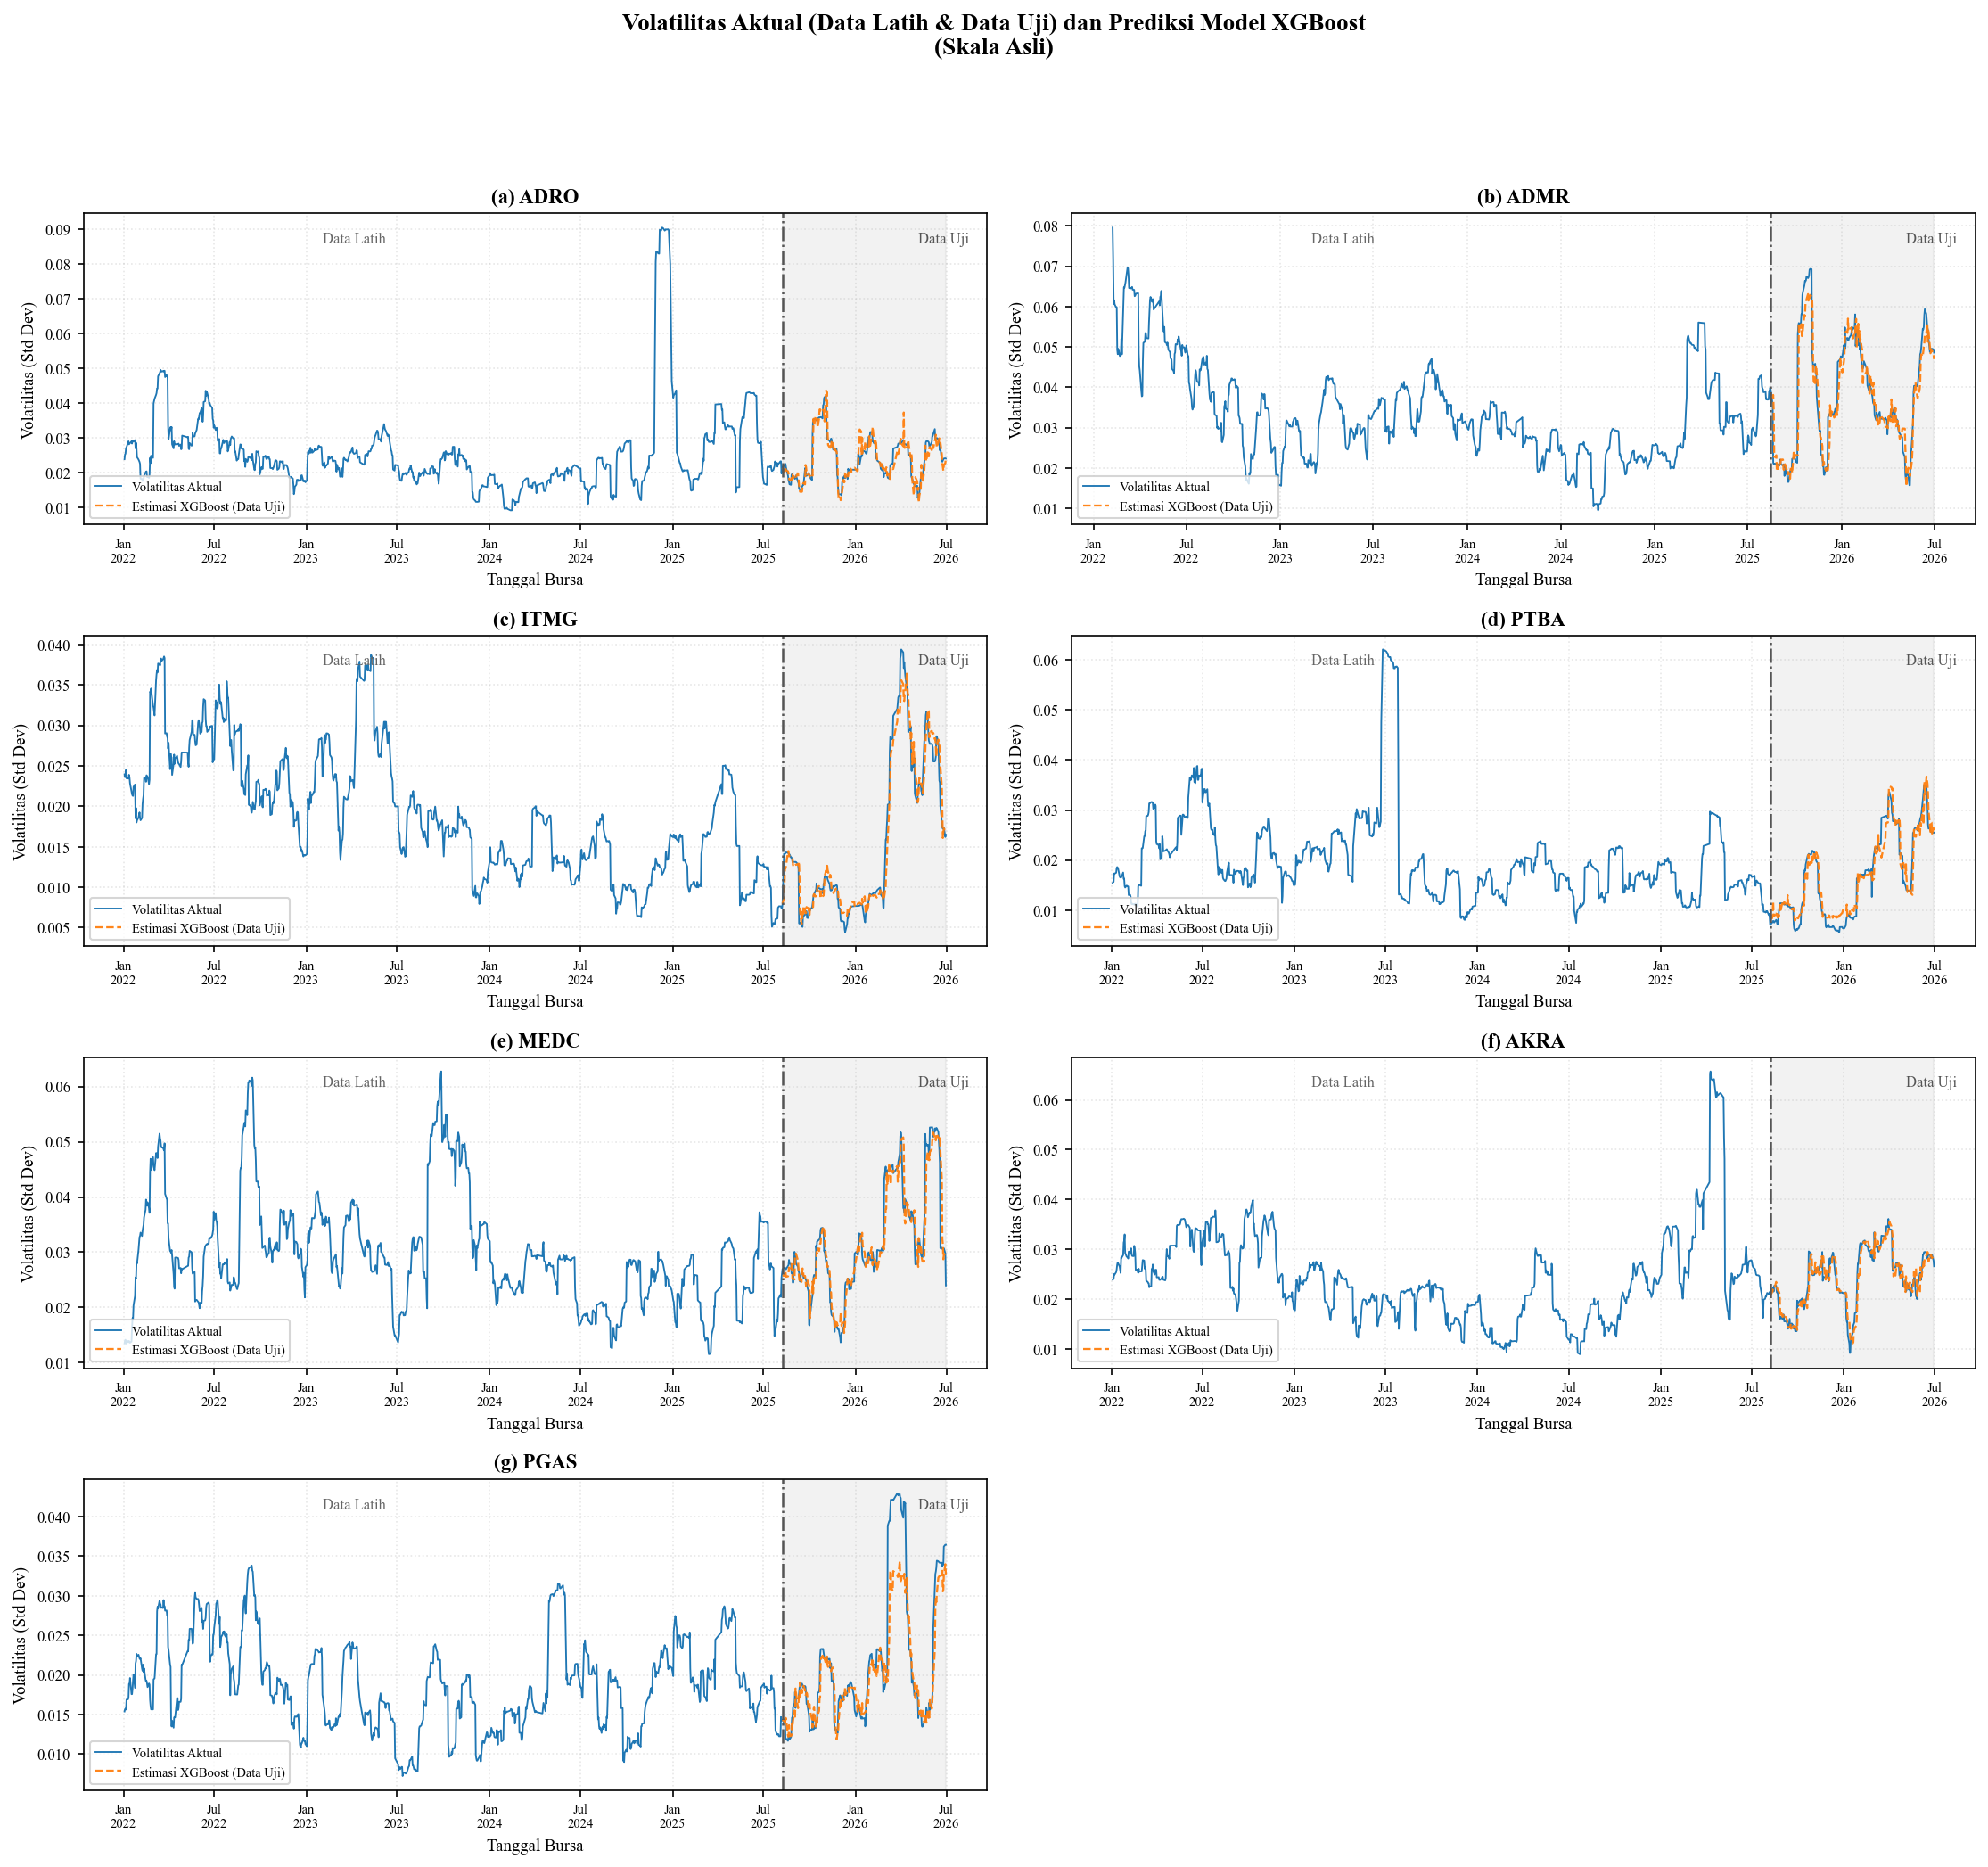

💾 tersimpan: E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\06_dokumen_tesis\gambar\model\gambar_xgboost_latih_uji_per_emiten.png


In [11]:
# ==============================================================================
# CELL 8B — GRAFIK VOLATILITAS: DATA LATIH + DATA UJI + PREDIKSI XGBOOST (per emiten)
# ==============================================================================
import string, numpy as np, pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt, matplotlib.dates as mdates

plt.rcParams.update({'font.family':'Times New Roman','font.size':11,
                     'axes.titlesize':11,'axes.labelsize':9,'figure.dpi':150})

# --- Sumber volatilitas SKALA ASLI (periode penuh 2022–2026) ---
if 'DIR_FINAL' not in globals():
    ROOT_LOCAL = Path.cwd()
    for _ in range(8):
        if (ROOT_LOCAL / '03_dataset').exists():
            break
        ROOT_LOCAL = ROOT_LOCAL.parent
    if not (ROOT_LOCAL / '03_dataset').exists():
        ROOT_LOCAL = Path(
            r'E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS'
            r'\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026')
    DIR_FINAL = ROOT_LOCAL / '03_dataset' / 'final'

src = DIR_FINAL / 'dataset_gabungan_X1X2Y.csv'
dfv = pd.read_csv(src)

# normalisasi nama kolom: pastikan ada 'Tanggal', 'Kode_Emiten', 'Volatilitas_Return'
if 'Tanggal' in dfv.columns:
    dfv['Tanggal'] = pd.to_datetime(dfv['Tanggal'])
elif 'Date' in dfv.columns:
    dfv['Tanggal'] = pd.to_datetime(dfv['Date'])
else:
    raise KeyError("Kolom tanggal tidak ditemukan: cari 'Tanggal' atau 'Date' di dataset_gabungan_X1X2Y.csv")
if 'Kode_Emiten' not in dfv.columns and 'Emiten' in dfv.columns:
    dfv['Kode_Emiten'] = dfv['Emiten']
if 'Volatilitas_Return' not in dfv.columns and 'Volatilitas_Target' in dfv.columns:
    dfv['Volatilitas_Return'] = dfv['Volatilitas_Target']

dfv = dfv[['Tanggal','Kode_Emiten','Volatilitas_Return']].rename(
        columns={'Tanggal':'Date','Kode_Emiten':'Emiten','Volatilitas_Return':'Vol'})

if 'dict_hasil_xgb' in globals() and isinstance(dict_hasil_xgb, dict) and dict_hasil_xgb:
    source_order = URUTAN_EMITEN if 'URUTAN_EMITEN' in globals() else list(dict_hasil_xgb.keys())
    emiten_ok = [e for e in source_order if e in dict_hasil_xgb]
else:
    emiten_ok = sorted(dfv['Emiten'].unique())

ncol=2; nrow=int(np.ceil(len(emiten_ok)/ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(15, 3.5*nrow)); axes=np.array(axes).ravel()
fig.suptitle('Volatilitas Aktual (Data Latih & Data Uji) dan Prediksi Model XGBoost\n(Skala Asli)',
             fontweight='bold', fontsize=13, y=0.995)

for i,(ax,emiten) in enumerate(zip(axes, emiten_ok)):
    if 'dict_hasil_xgb' not in globals() or not dict_hasil_xgb:
        raise NameError(
            "❌ dict_hasil_xgb tidak ditemukan. "
            "Jalankan CELL INDEX: 4 (Training & Evaluasi XGBoost) terlebih dahulu."
        )
    te = dict_hasil_xgb[emiten].copy()
    te['Date'] = pd.to_datetime(te['Date'])
    split_date = te['Date'].min()

    # aktual skala asli, periode LATIH (< split)
    va = dfv[(dfv['Emiten']==emiten) & (dfv['Date'] < split_date)].sort_values('Date')

    # garis aktual menyambung: latih (dari file) + uji (dari hasil model)
    aktual = pd.concat([
        va[['Date','Vol']].rename(columns={'Vol':'v'}),
        te[['Date']].assign(v=te['Y_Aktual'].values)
    ]).sort_values('Date')

    # ── WARNA SERAGAM: biru = aktual, oranye = prediksi, abu-abu = area uji ──
    ax.plot(aktual['Date'], aktual['v'], color='#1f77b4', lw=0.9, label='Volatilitas Aktual')
    ax.plot(te['Date'], te['Y_Prediksi'], color='#ff7f0e', lw=1.1, ls='--', alpha=0.95,
            label='Estimasi XGBoost (Data Uji)')

    ax.axvline(split_date, color='#555', lw=1.2, ls='-.')
    ax.axvspan(split_date, aktual['Date'].max(), color='#cccccc', alpha=0.25)
    ax.text(0.30, 0.94, 'Data Latih', transform=ax.transAxes, fontsize=8,
            ha='center', va='top', color='#666')
    ax.text(0.98, 0.94, 'Data Uji', transform=ax.transAxes, fontsize=8,
            ha='right', va='top', color='#555')

    ax.set_title(f'({string.ascii_lowercase[i]}) {emiten}', fontweight='bold')
    ax.set_xlabel('Tanggal Bursa'); ax.set_ylabel('Volatilitas (Std Dev)')
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1,7]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))
    ax.tick_params(axis='x',labelsize=7); ax.tick_params(axis='y',labelsize=8)
    ax.legend(fontsize=7, loc='lower left'); ax.grid(True, alpha=0.3, ls=':')

for ax in axes[len(emiten_ok):]: ax.axis('off')
plt.tight_layout(rect=[0,0,1,0.95])
jalur = DIR_GAMBAR / 'gambar_xgboost_latih_uji_per_emiten.png'
plt.savefig(jalur, dpi=150, bbox_inches='tight'); plt.show()
print("💾 tersimpan:", jalur.resolve())

## 🔍 CELL 9 — Analisis SHAP: Summary Plot per Emiten (→ Gambar 4.X)
> **Tujuan:** menjelaskan *bagaimana* dan *ke arah mana* setiap fitur memengaruhi prediksi
> volatilitas (bukan sekadar besar kontribusinya seperti feature importance).
> Nilai SHAP dihitung pada **data uji** dengan `TreeExplainer` (Lundberg & Lee, 2017).
>
> ⚠️ Prasyarat: `pip install shap`

SHAP versi: 0.51.0


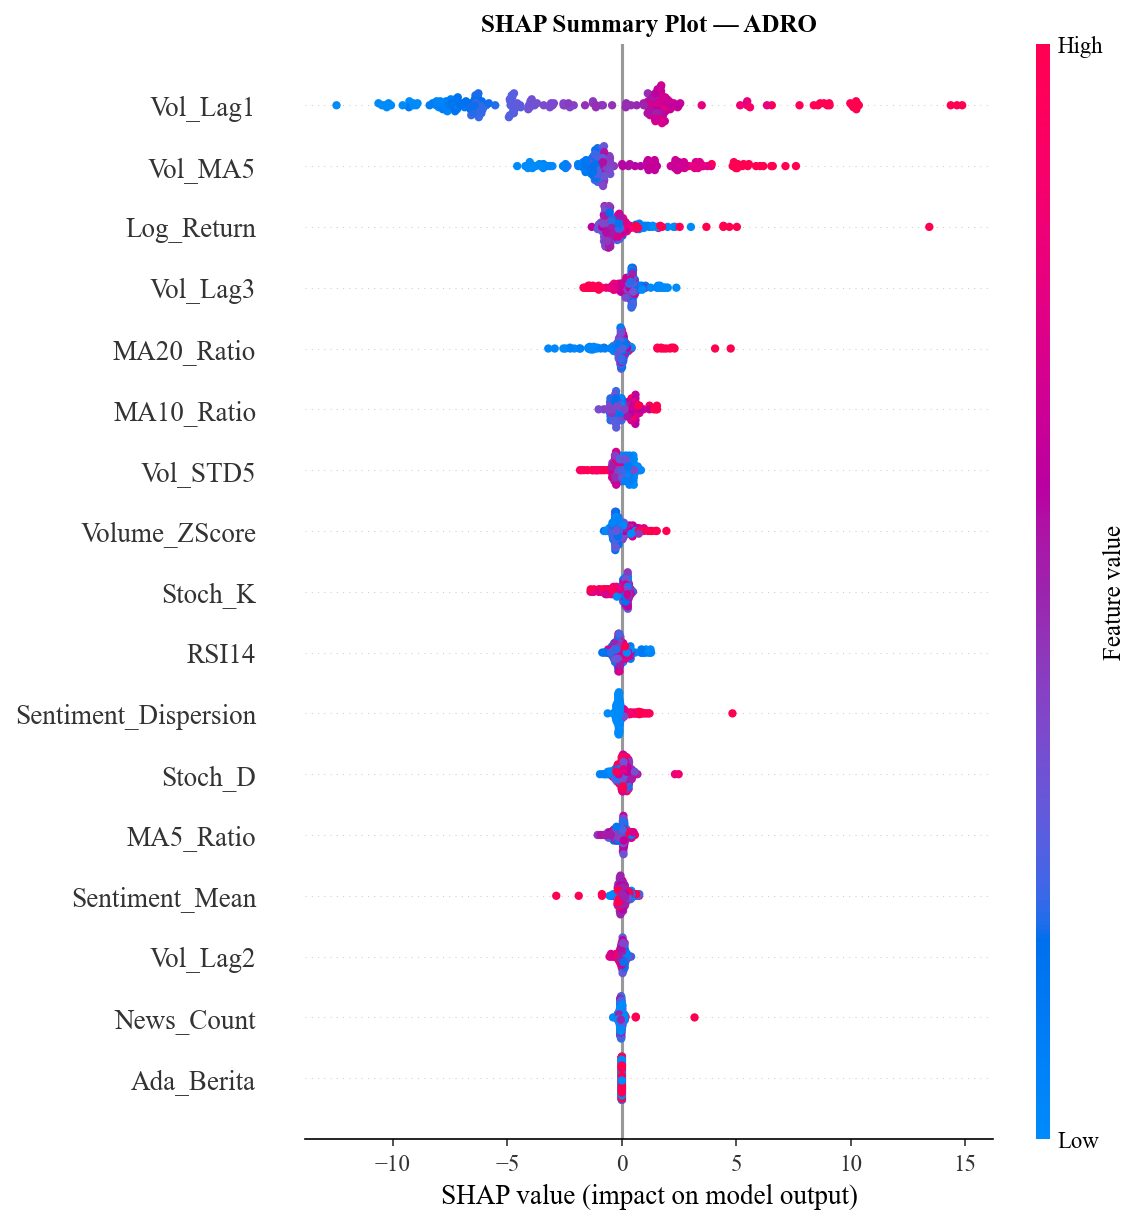

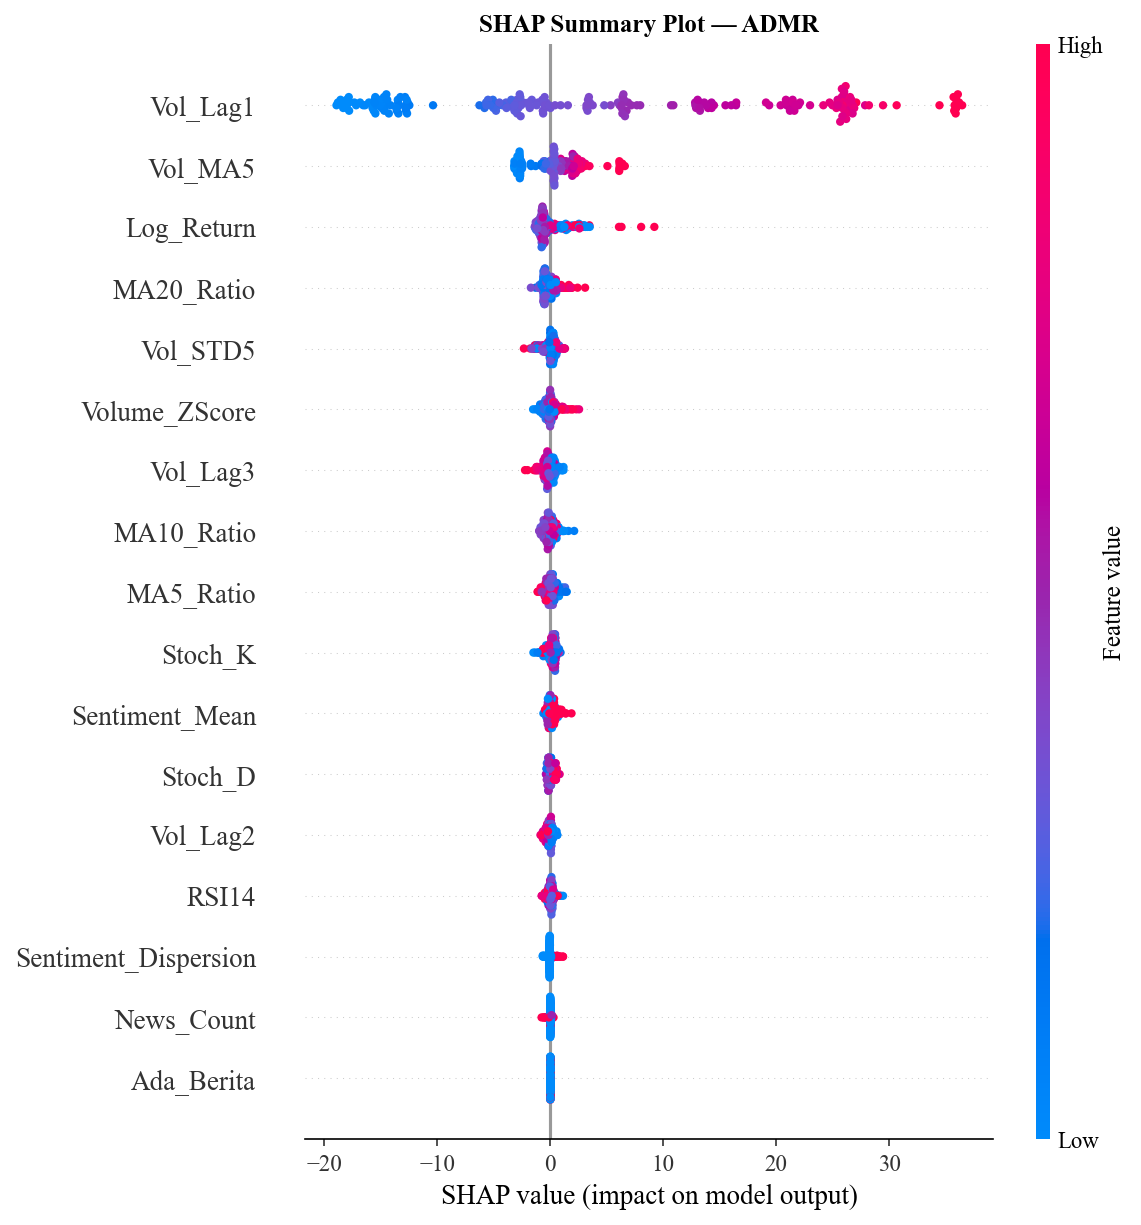

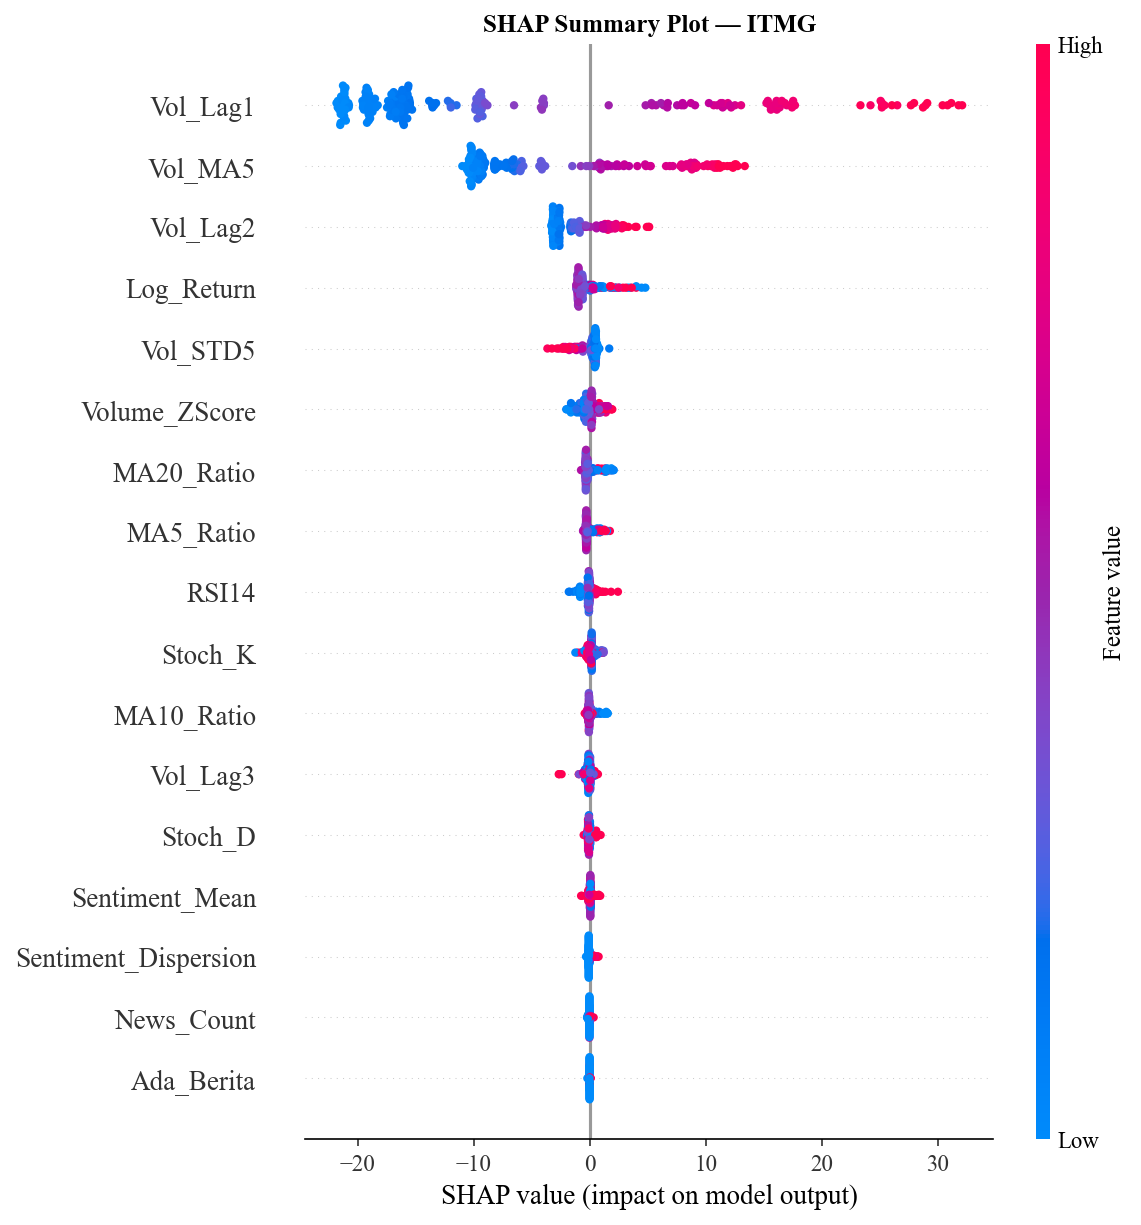

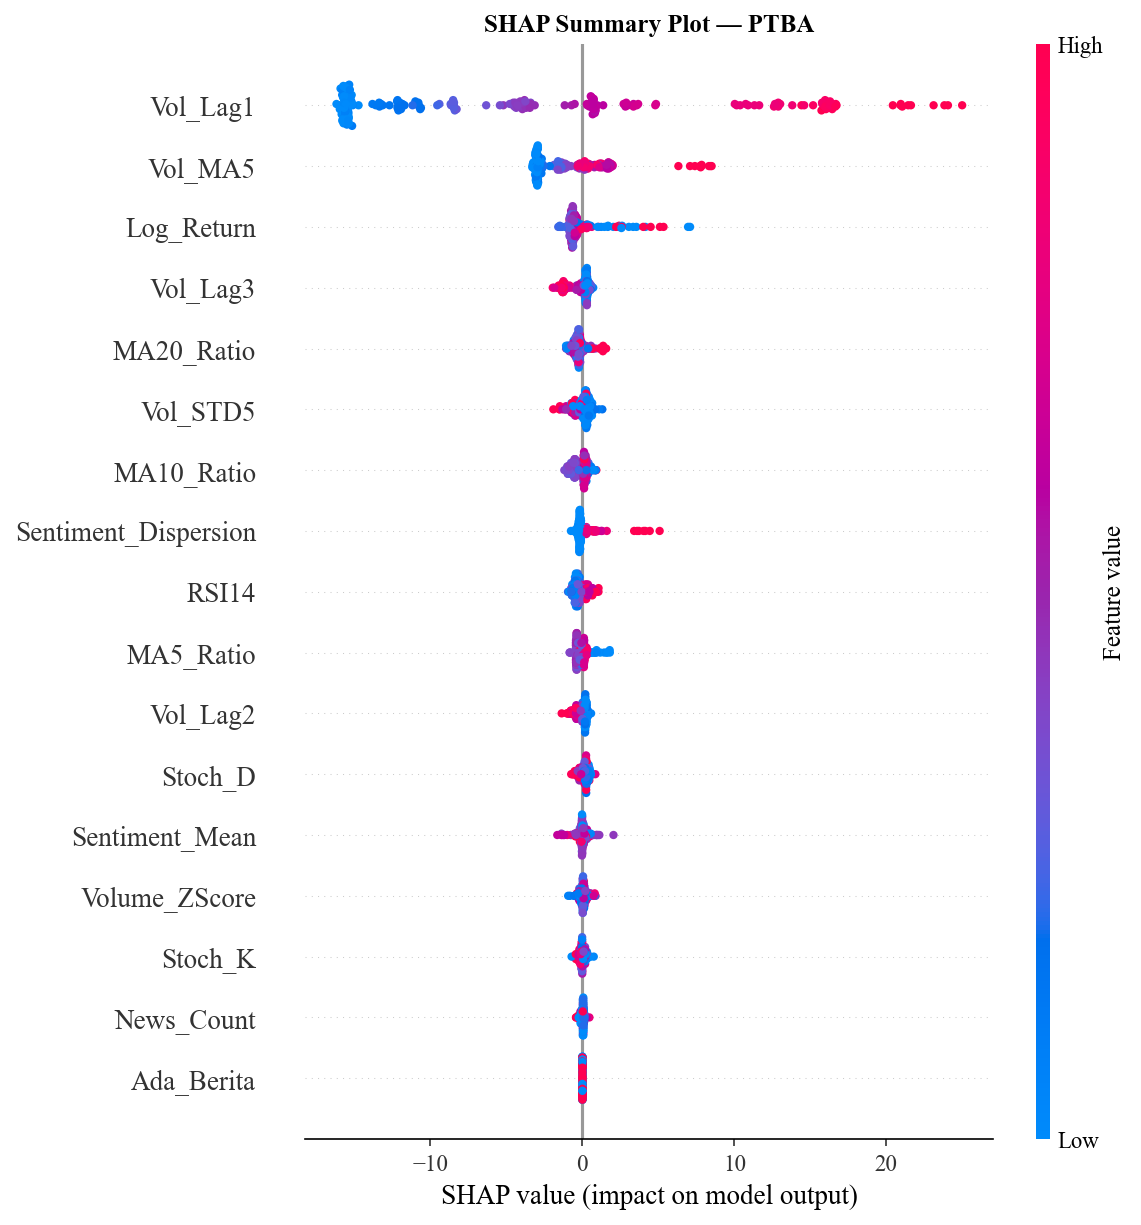

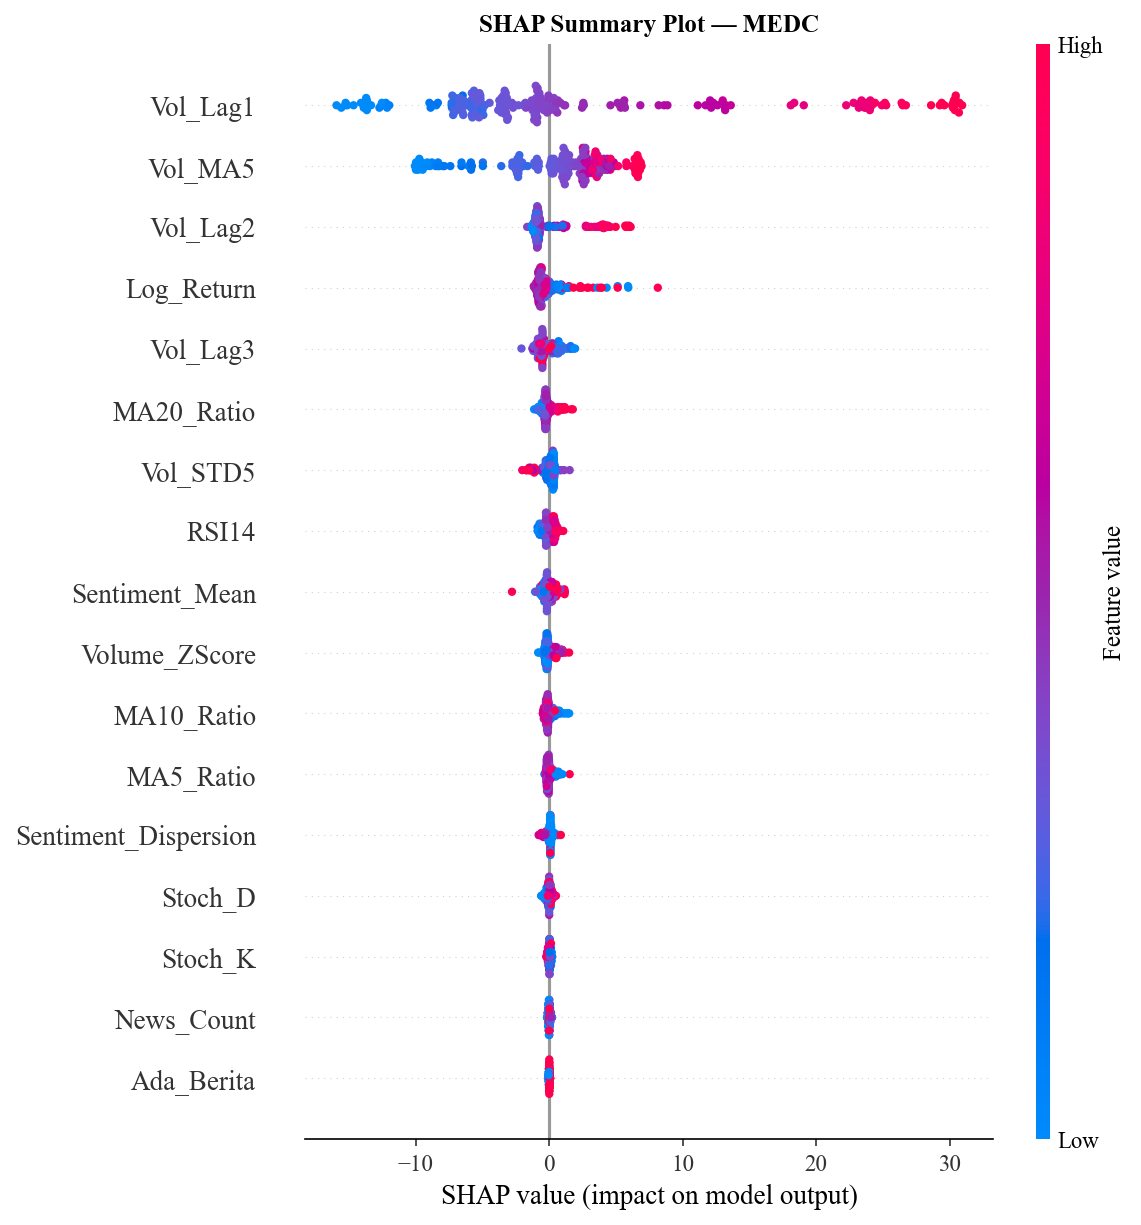

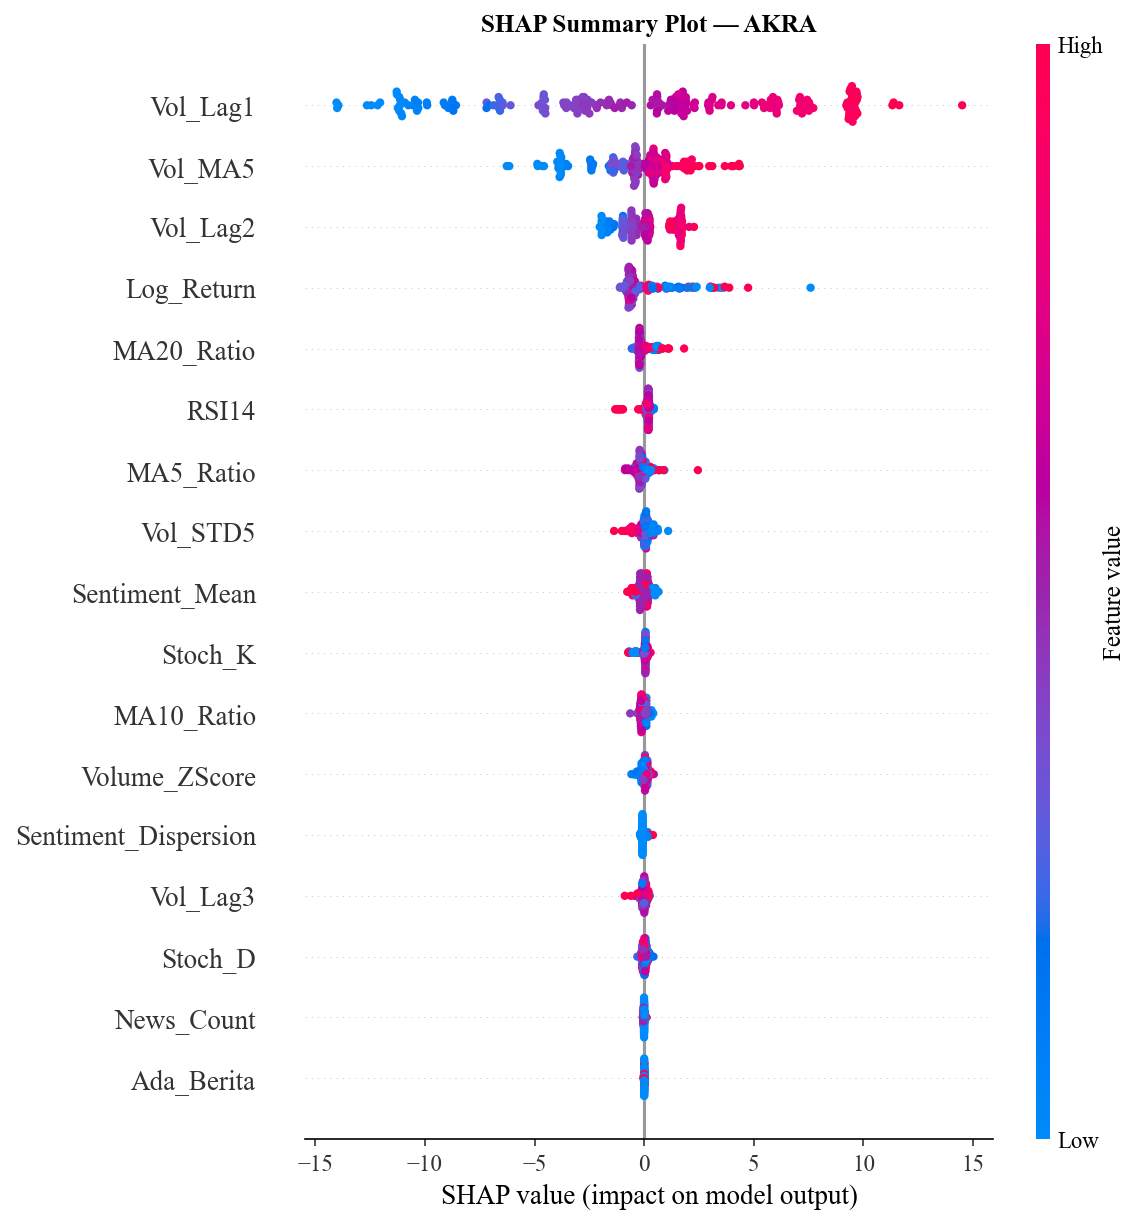

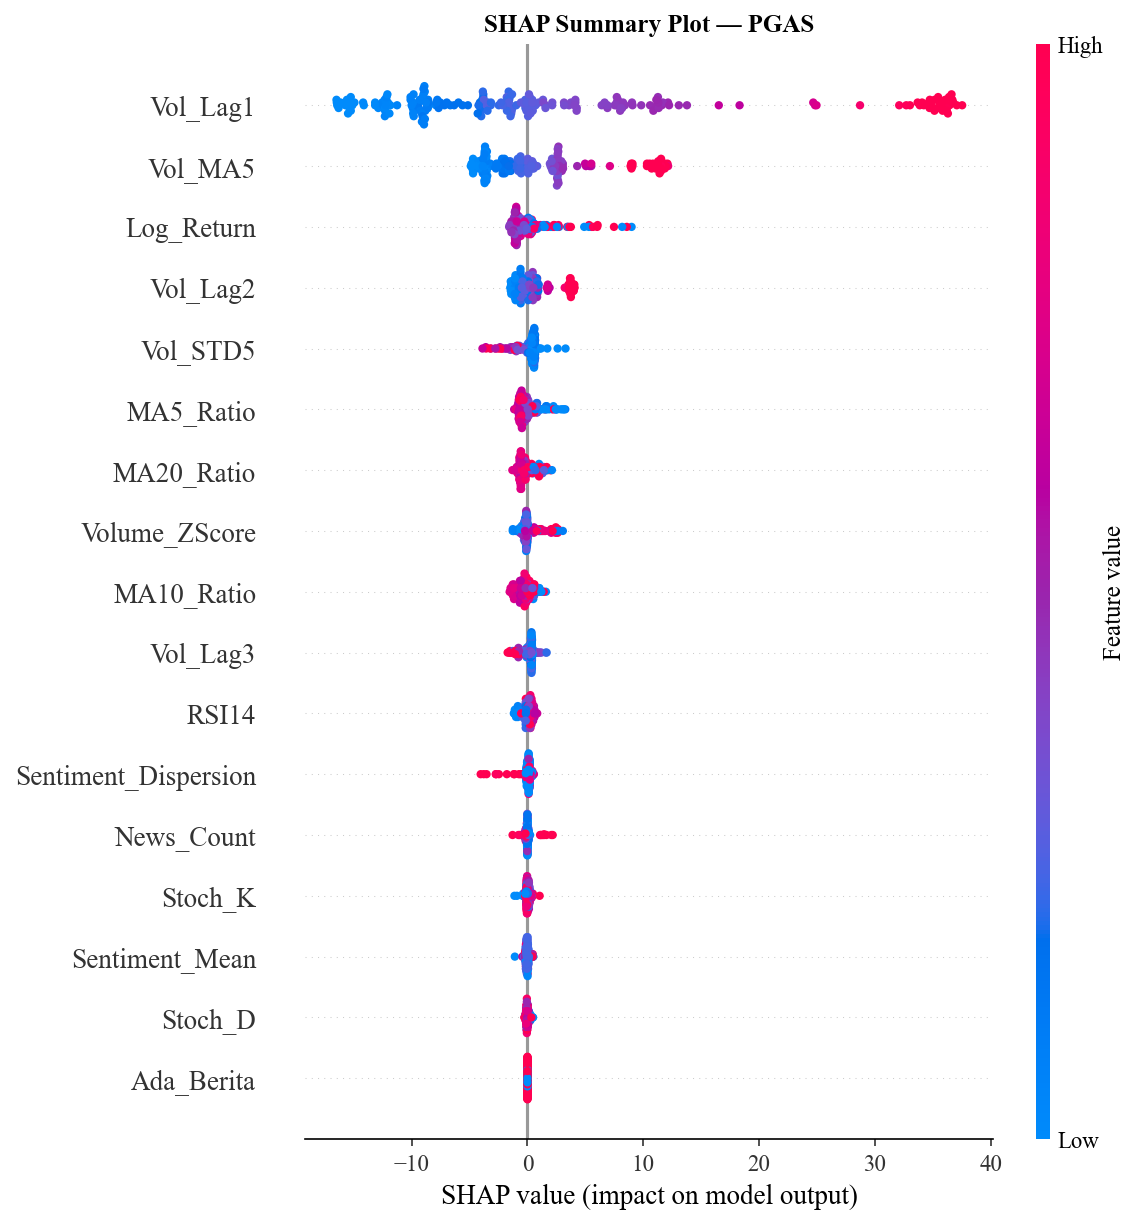


💾 7 gambar SHAP summary tersimpan di e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\06_dokumen_tesis\gambar\model


In [12]:
# ============================================================
# CELL 9 — SHAP SUMMARY (BEESWARM) PER EMITEN
# ============================================================
try:
    import shap
except ImportError:
    raise ImportError("Library shap belum terpasang. Jalankan: pip install shap")

print(f'SHAP versi: {shap.__version__}')
emiten_ok = [e for e in URUTAN_EMITEN if e in dict_hasil_xgb]

dict_shap = {}   # simpan hasil untuk cell berikutnya (agregat & dependence)

for emiten in emiten_ok:
    model   = joblib.load(DIR_MODEL / f'xgboost_{emiten}.pkl')
    kolom_x = list(dict_kolom_x[emiten])
    df_te   = dict_test[emiten].sort_values(
        'Tanggal' if 'Tanggal' in dict_test[emiten].columns else 'Date')

    # DataFrame (bukan .values) agar nama fitur ikut terbawa ke plot SHAP
    X_te = df_te[kolom_x].astype(float)

    explainer   = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(X_te)
    dict_shap[emiten] = {'shap_values': shap_values, 'X_te': X_te}

    # ── Beeswarm summary plot per emiten ──
    fig = plt.figure(figsize=(8, 5))
    shap.summary_plot(shap_values, X_te, show=False, max_display=17)
    plt.title(f'SHAP Summary Plot — {emiten}', fontweight='bold', fontsize=12)
    plt.tight_layout()
    plt.savefig(DIR_GAMBAR / f'gambar_shap_summary_{emiten}.png',
                dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)

print(f'\n💾 {len(dict_shap)} gambar SHAP summary tersimpan di {DIR_GAMBAR}')


## 🔍 CELL 10 — SHAP Bar Agregat & Kontribusi Sentimen (→ Gambar 4.X & Tabel 4.X)
> Rata-rata |SHAP| lintas emiten sebagai ukuran **kontribusi global** tiap fitur.
> Fitur sentimen (X2) diberi warna oranye — berguna untuk narasi pengujian
> hipotesis "apakah sentimen berita berkontribusi terhadap prediksi volatilitas".

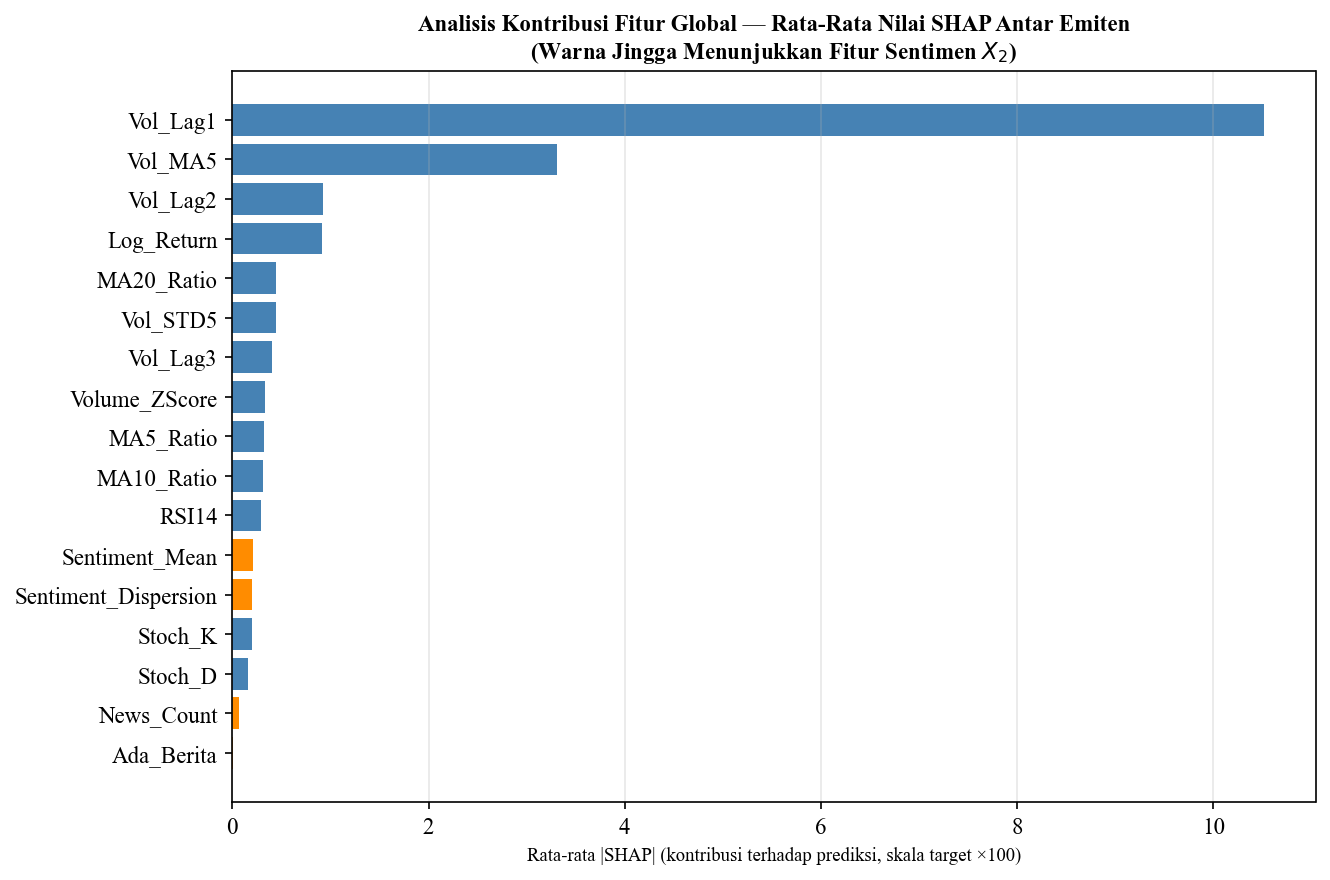

Emiten                    ADRO       ADMR       ITMG       PTBA      MEDC      AKRA       PGAS  RATA-RATA
Fitur                                                                                                    
Vol_Lag1              4.866699  14.424036  16.086920  11.159536  9.381989  5.659390  12.019905  10.514068
Vol_MA5               2.013098   1.884405   8.096688   2.188373  3.611660  1.408140   3.933987   3.305193
Vol_Lag2              0.093519   0.213992   2.273108   0.275089  1.519406  0.963659   1.131738   0.924359
Log_Return            0.726318   1.070417   0.919368   0.850783  0.835360  0.871269   1.151508   0.917860
MA20_Ratio            0.432980   0.516471   0.478773   0.418787  0.392810  0.277103   0.582912   0.442834
Vol_STD5              0.329995   0.424779   0.677186   0.389393  0.354029  0.215901   0.689698   0.440140
Vol_Lag3              0.550753   0.393642   0.192669   0.490420  0.629823  0.088913   0.455668   0.400270
Volume_ZScore         0.322516   0.402756   0.

In [13]:
# ============================================================
# CELL 10 — SHAP BAR AGREGAT (MEAN |SHAP| LINTAS EMITEN)
# ============================================================
FITUR_SENTIMEN = ['Sentiment_Mean', 'Sentiment_Dispersion', 'News_Count', 'Ada_Berita']

rows_shap = []
for emiten, d in dict_shap.items():
    mean_abs = np.abs(d['shap_values']).mean(axis=0)
    for f, v in zip(d['X_te'].columns, mean_abs):
        rows_shap.append({'Emiten': emiten, 'Fitur': f, 'Mean_Abs_SHAP': float(v)})

df_shap = pd.DataFrame(rows_shap)

# ── Agregat: rata-rata mean|SHAP| lintas emiten ──
agg = (df_shap.groupby('Fitur')['Mean_Abs_SHAP']
       .mean().sort_values())

fig, ax = plt.subplots(figsize=(9, 6))
warna = ['darkorange' if f in FITUR_SENTIMEN else 'steelblue' for f in agg.index]
ax.barh(agg.index, agg.values, color=warna)
ax.set_xlabel('Rata-rata |SHAP| (kontribusi terhadap prediksi, skala target ×100)')
ax.set_title('Analisis Kontribusi Fitur Global — Rata-Rata Nilai SHAP Antar Emiten\n'
             '(Warna Jingga Menunjukkan Fitur Sentimen $X_2$)', fontweight='bold')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(DIR_GAMBAR / 'gambar_shap_bar_agregat.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Tabel pivot untuk lampiran tesis ──
pivot_shap = (df_shap.pivot(index='Fitur', columns='Emiten', values='Mean_Abs_SHAP')
              .reindex(columns=emiten_ok))
pivot_shap['RATA-RATA'] = pivot_shap.mean(axis=1)
pivot_shap = pivot_shap.sort_values('RATA-RATA', ascending=False).round(6)
pivot_shap.to_csv(DIR_TABEL / 'tabel_shap_per_emiten.csv', encoding='utf-8-sig')

# ── Ringkasan proporsi kontribusi sentimen (untuk narasi Bab IV) ──
total   = pivot_shap['RATA-RATA'].sum()
sen     = pivot_shap.loc[pivot_shap.index.isin(FITUR_SENTIMEN), 'RATA-RATA'].sum()
print(pivot_shap.to_string())
print('=' * 70)
print(f'📌 Proporsi kontribusi fitur SENTIMEN (X2): {sen/total*100:.2f}% '
      f'dari total |SHAP|')
print(f'📌 Proporsi kontribusi fitur TEKNIKAL (X1): {(total-sen)/total*100:.2f}%')
print('💾 gambar_shap_bar_agregat.png & tabel_shap_per_emiten.csv tersimpan')


## 🔍 CELL 11 — SHAP Dependence Plot Fitur Sentimen (→ Gambar 4.X)
> Memperlihatkan **hubungan fungsional** antara nilai `Sentiment_Mean` dan dampaknya
> terhadap prediksi volatilitas — mendukung pembahasan arah pengaruh sentimen
> (misal: sentimen negatif → volatilitas prediksi naik).

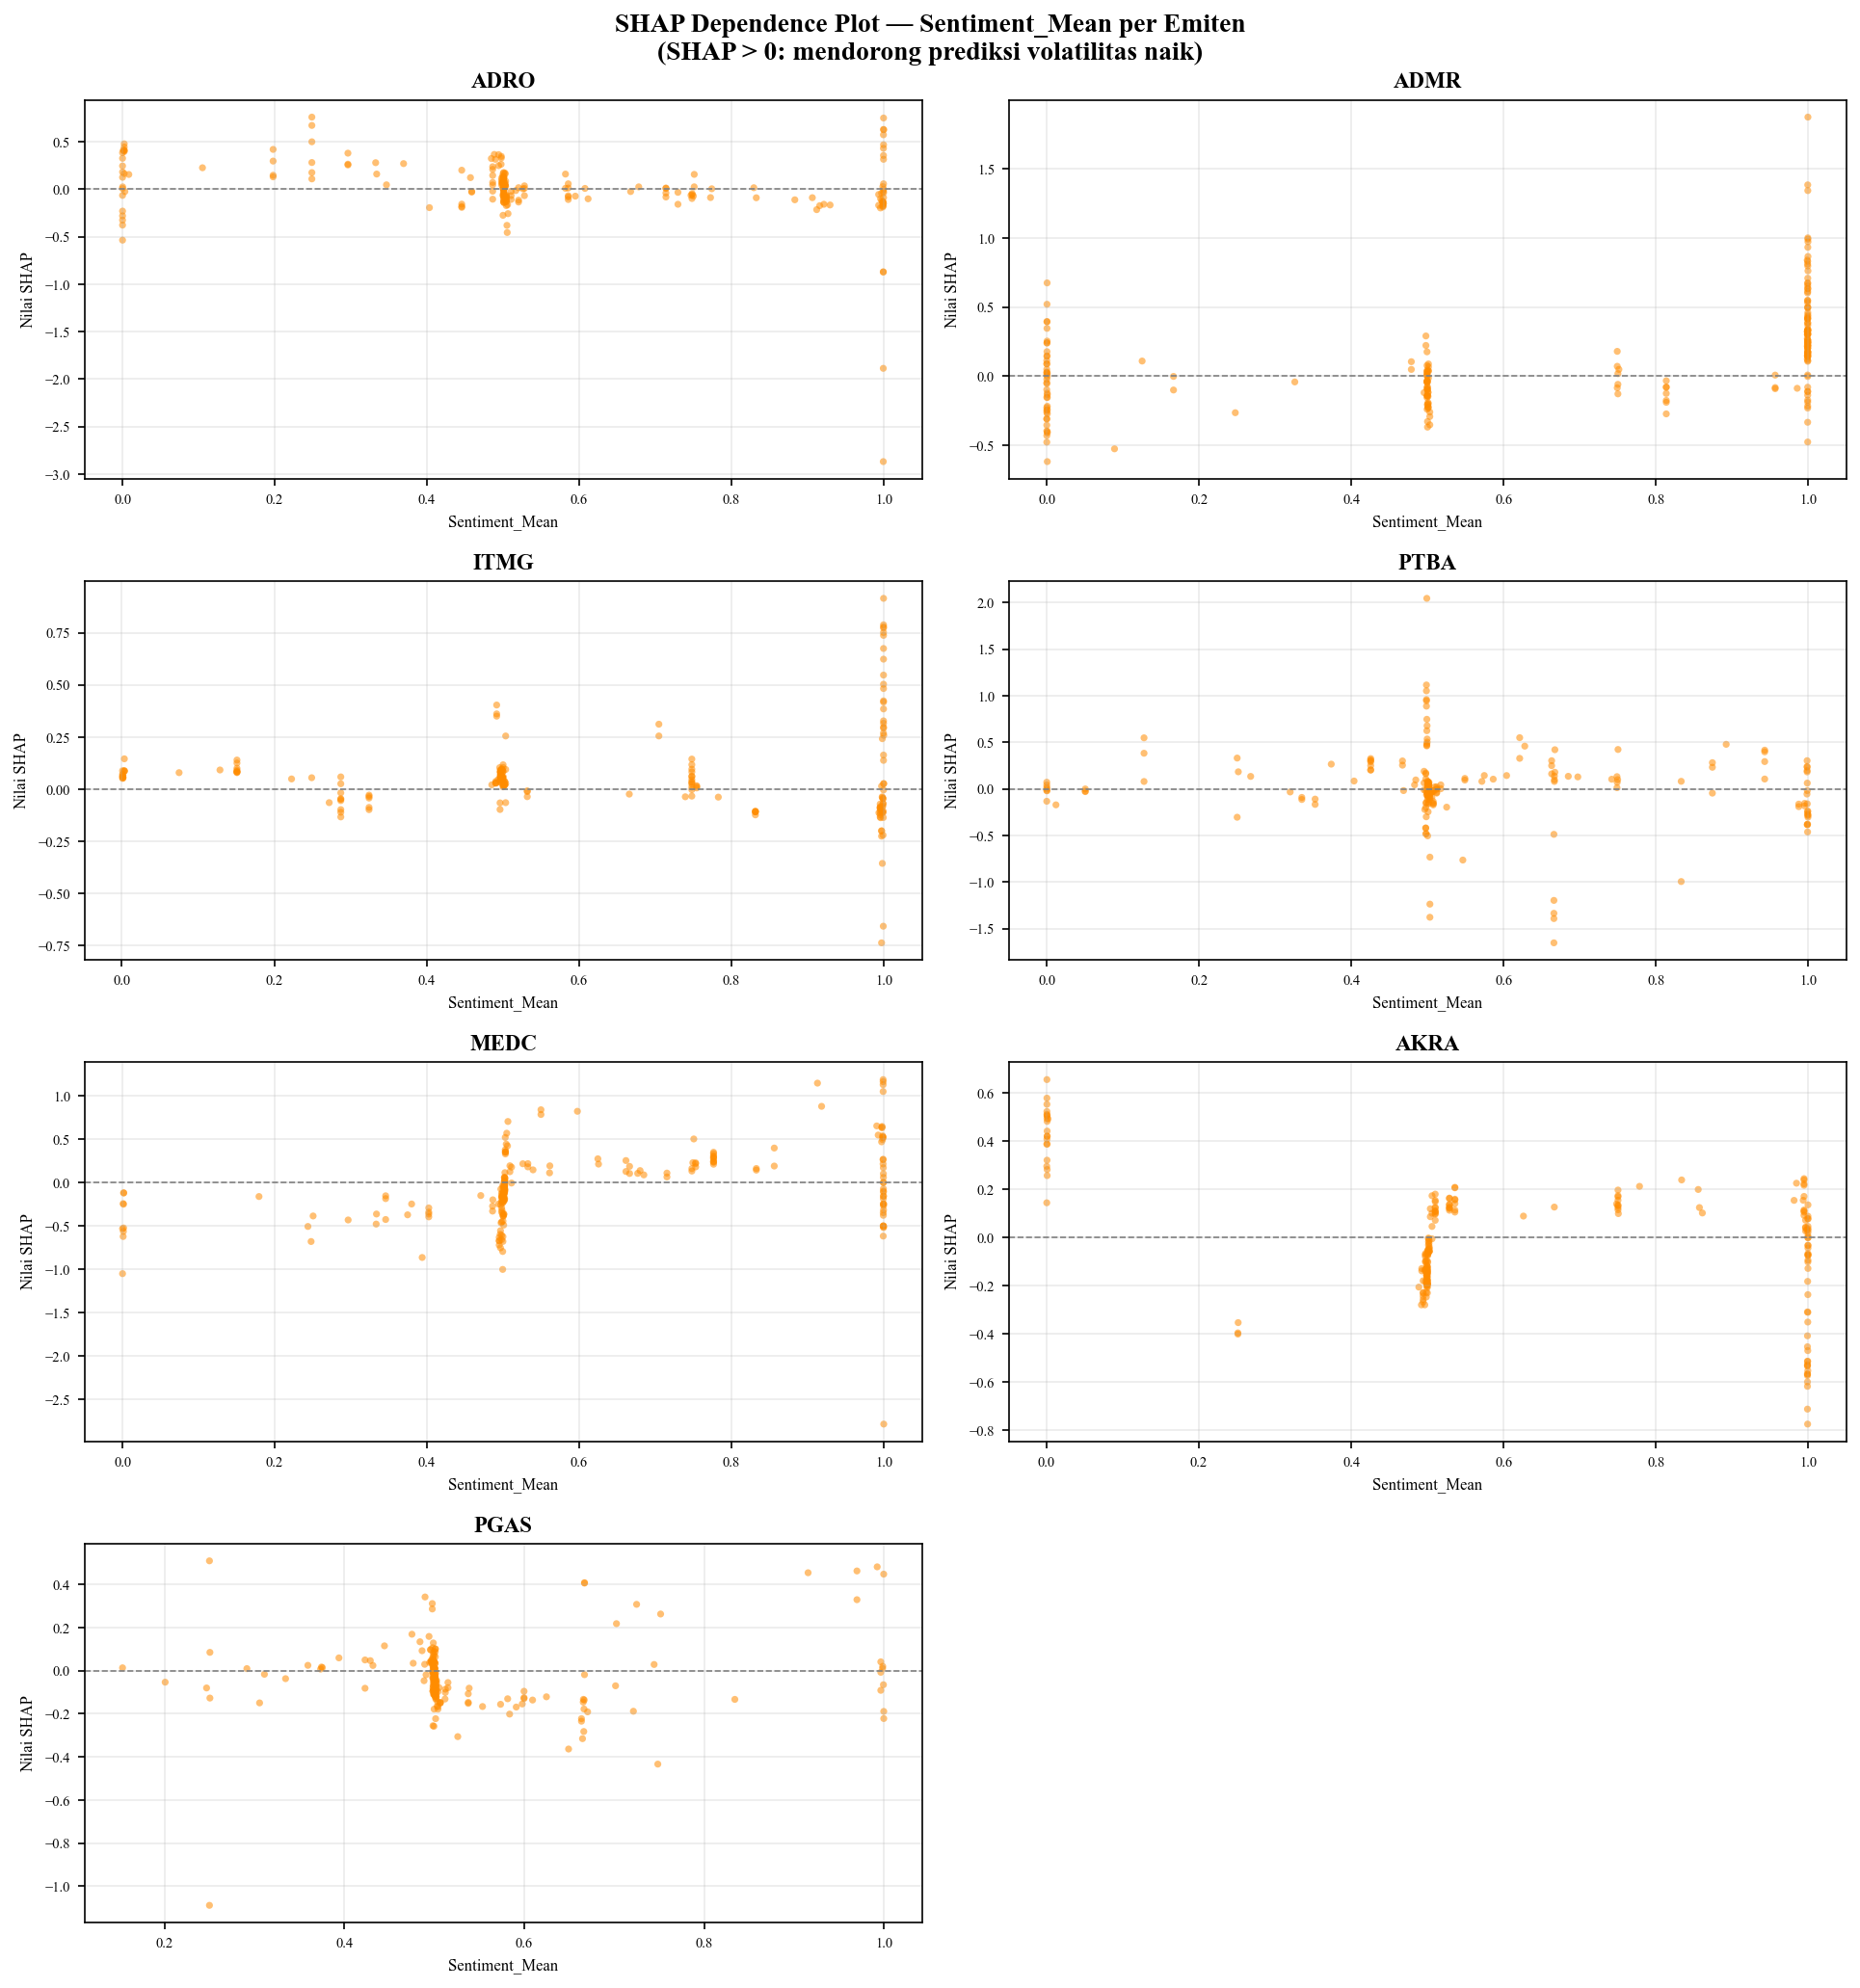

💾 gambar SHAP dependence tersimpan


In [14]:
# ============================================================
# CELL 11 — SHAP DEPENDENCE PLOT: Sentiment_Mean per Emiten
# ============================================================
FITUR_UTAMA = 'Sentiment_Mean'

ncol = 2; nrow = int(np.ceil(len(emiten_ok) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(13, 3.5 * nrow))
axes = np.array(axes).ravel()

for ax, emiten in zip(axes, emiten_ok):
    d = dict_shap[emiten]
    if FITUR_UTAMA not in d['X_te'].columns:
        ax.axis('off'); continue
    idx = list(d['X_te'].columns).index(FITUR_UTAMA)
    ax.scatter(d['X_te'][FITUR_UTAMA], d['shap_values'][:, idx],
               s=12, alpha=0.55, c='darkorange', edgecolors='none')
    ax.axhline(0, color='grey', lw=0.8, ls='--')
    ax.set_title(emiten, fontweight='bold')
    ax.set_xlabel(FITUR_UTAMA, fontsize=8)
    ax.set_ylabel('Nilai SHAP', fontsize=8)
    ax.tick_params(labelsize=7); ax.grid(alpha=0.25)

for ax in axes[len(emiten_ok):]:
    ax.axis('off')

plt.suptitle(f'SHAP Dependence Plot — {FITUR_UTAMA} per Emiten\n'
             '(SHAP > 0: mendorong prediksi volatilitas naik)', fontweight='bold')
plt.tight_layout()
plt.savefig(DIR_GAMBAR / f'gambar_shap_dependence_{FITUR_UTAMA.lower()}.png',
            dpi=150, bbox_inches='tight')
plt.show()
print('💾 gambar SHAP dependence tersimpan')


## 📊 CELL 12 — Perbandingan 3 Tipe Feature Importance: Weight vs Gain vs Cover (→ Gambar 4.X)
> `feature_importances_` bawaan XGBoost hanya satu sudut pandang. Perbandingan
> **weight** (frekuensi split), **gain** (kontribusi penurunan loss), dan **cover**
> (cakupan sampel) memberi gambaran lebih utuh — *gain* umumnya paling relevan
> untuk interpretasi akademik (Chen & Guestrin, 2016).

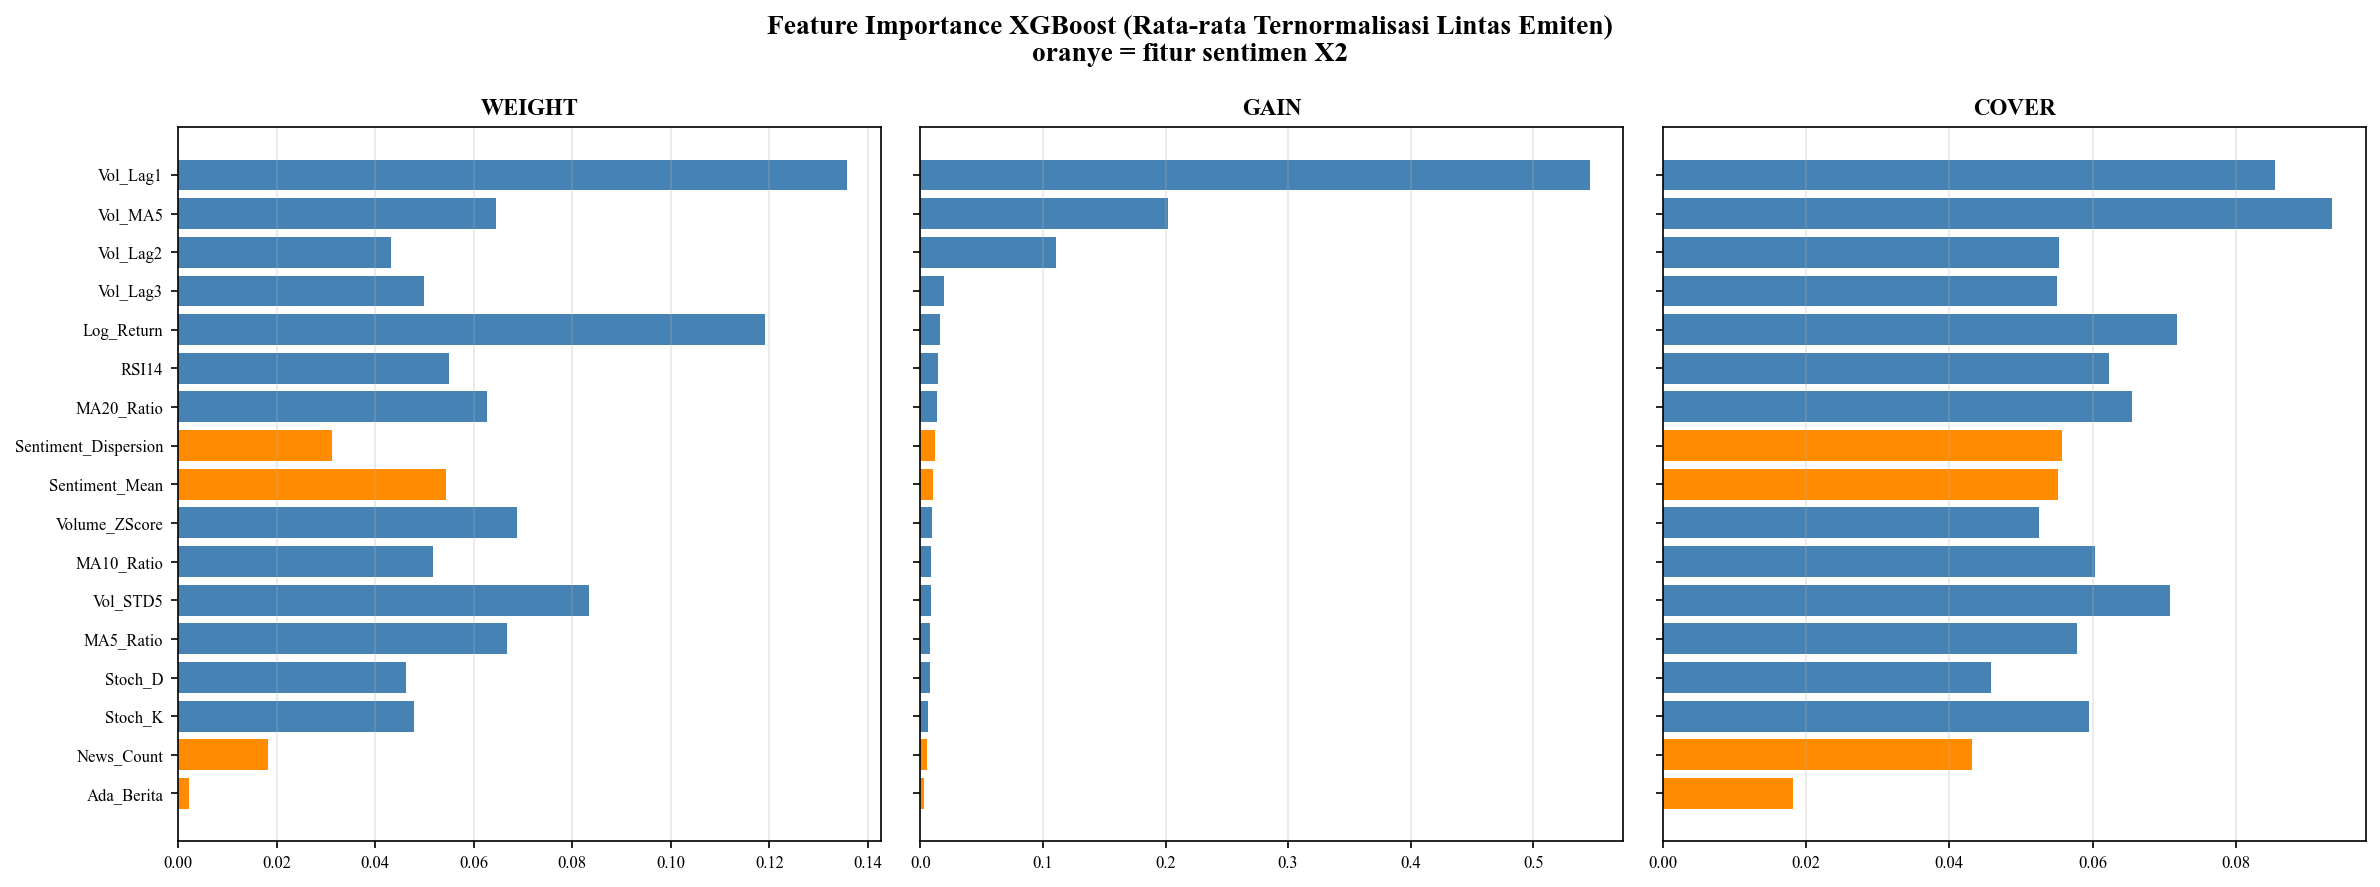

💾 gambar & tabel importance 3 tipe tersimpan


In [15]:
# ============================================================
# CELL 12 — IMPORTANCE: WEIGHT vs GAIN vs COVER (agregat lintas emiten)
# ============================================================
TIPE_IMPORTANCE = ['weight', 'gain', 'cover']
rows = []

for emiten in emiten_ok:
    model   = joblib.load(DIR_MODEL / f'xgboost_{emiten}.pkl')
    kolom_x = list(dict_kolom_x[emiten])
    booster = model.get_booster()
    # Model dilatih dgn numpy array → fitur bernama f0,f1,... ; petakan kembali
    peta = {f'f{i}': nama for i, nama in enumerate(kolom_x)}
    for tipe in TIPE_IMPORTANCE:
        skor = booster.get_score(importance_type=tipe)
        # Normalisasi agar bisa dirata-rata lintas emiten
        tot = sum(skor.values()) or 1.0
        for k, v in skor.items():
            rows.append({'Emiten': emiten, 'Fitur': peta.get(k, k),
                         'Tipe': tipe, 'Skor': v / tot})

df_imp3 = pd.DataFrame(rows)
agg3 = (df_imp3.groupby(['Fitur', 'Tipe'])['Skor'].mean()
        .unstack('Tipe').fillna(0)
        .sort_values('gain', ascending=True))

fig, axes = plt.subplots(1, 3, figsize=(16, 6), sharey=True)
for ax, tipe in zip(axes, TIPE_IMPORTANCE):
    warna = ['darkorange' if f in FITUR_SENTIMEN else 'steelblue' for f in agg3.index]
    ax.barh(agg3.index, agg3[tipe], color=warna)
    ax.set_title(tipe.upper(), fontweight='bold')
    ax.grid(axis='x', alpha=0.3); ax.tick_params(labelsize=8)

plt.suptitle('Feature Importance XGBoost (Rata-rata Ternormalisasi Lintas Emiten)\n'
             'oranye = fitur sentimen X2', fontweight='bold')
plt.tight_layout()
plt.savefig(DIR_GAMBAR / 'gambar_importance_weight_gain_cover.png',
            dpi=150, bbox_inches='tight')
plt.show()

agg3.round(6).to_csv(DIR_TABEL / 'tabel_importance_3tipe_xgboost.csv',
                     encoding='utf-8-sig')
print('💾 gambar & tabel importance 3 tipe tersimpan')


## 📊 CELL 13 — Diagnostik Residual: Scatter Aktual–Prediksi & Distribusi Error (→ Gambar 4.X)
> Validasi kualitas prediksi secara visual:
> 1. **Scatter aktual vs prediksi** — semakin rapat ke garis diagonal 45°, semakin baik.
> 2. **Histogram residual** — residual ideal terdistribusi simetris di sekitar nol
>    (tidak ada bias sistematis over/under-estimate).

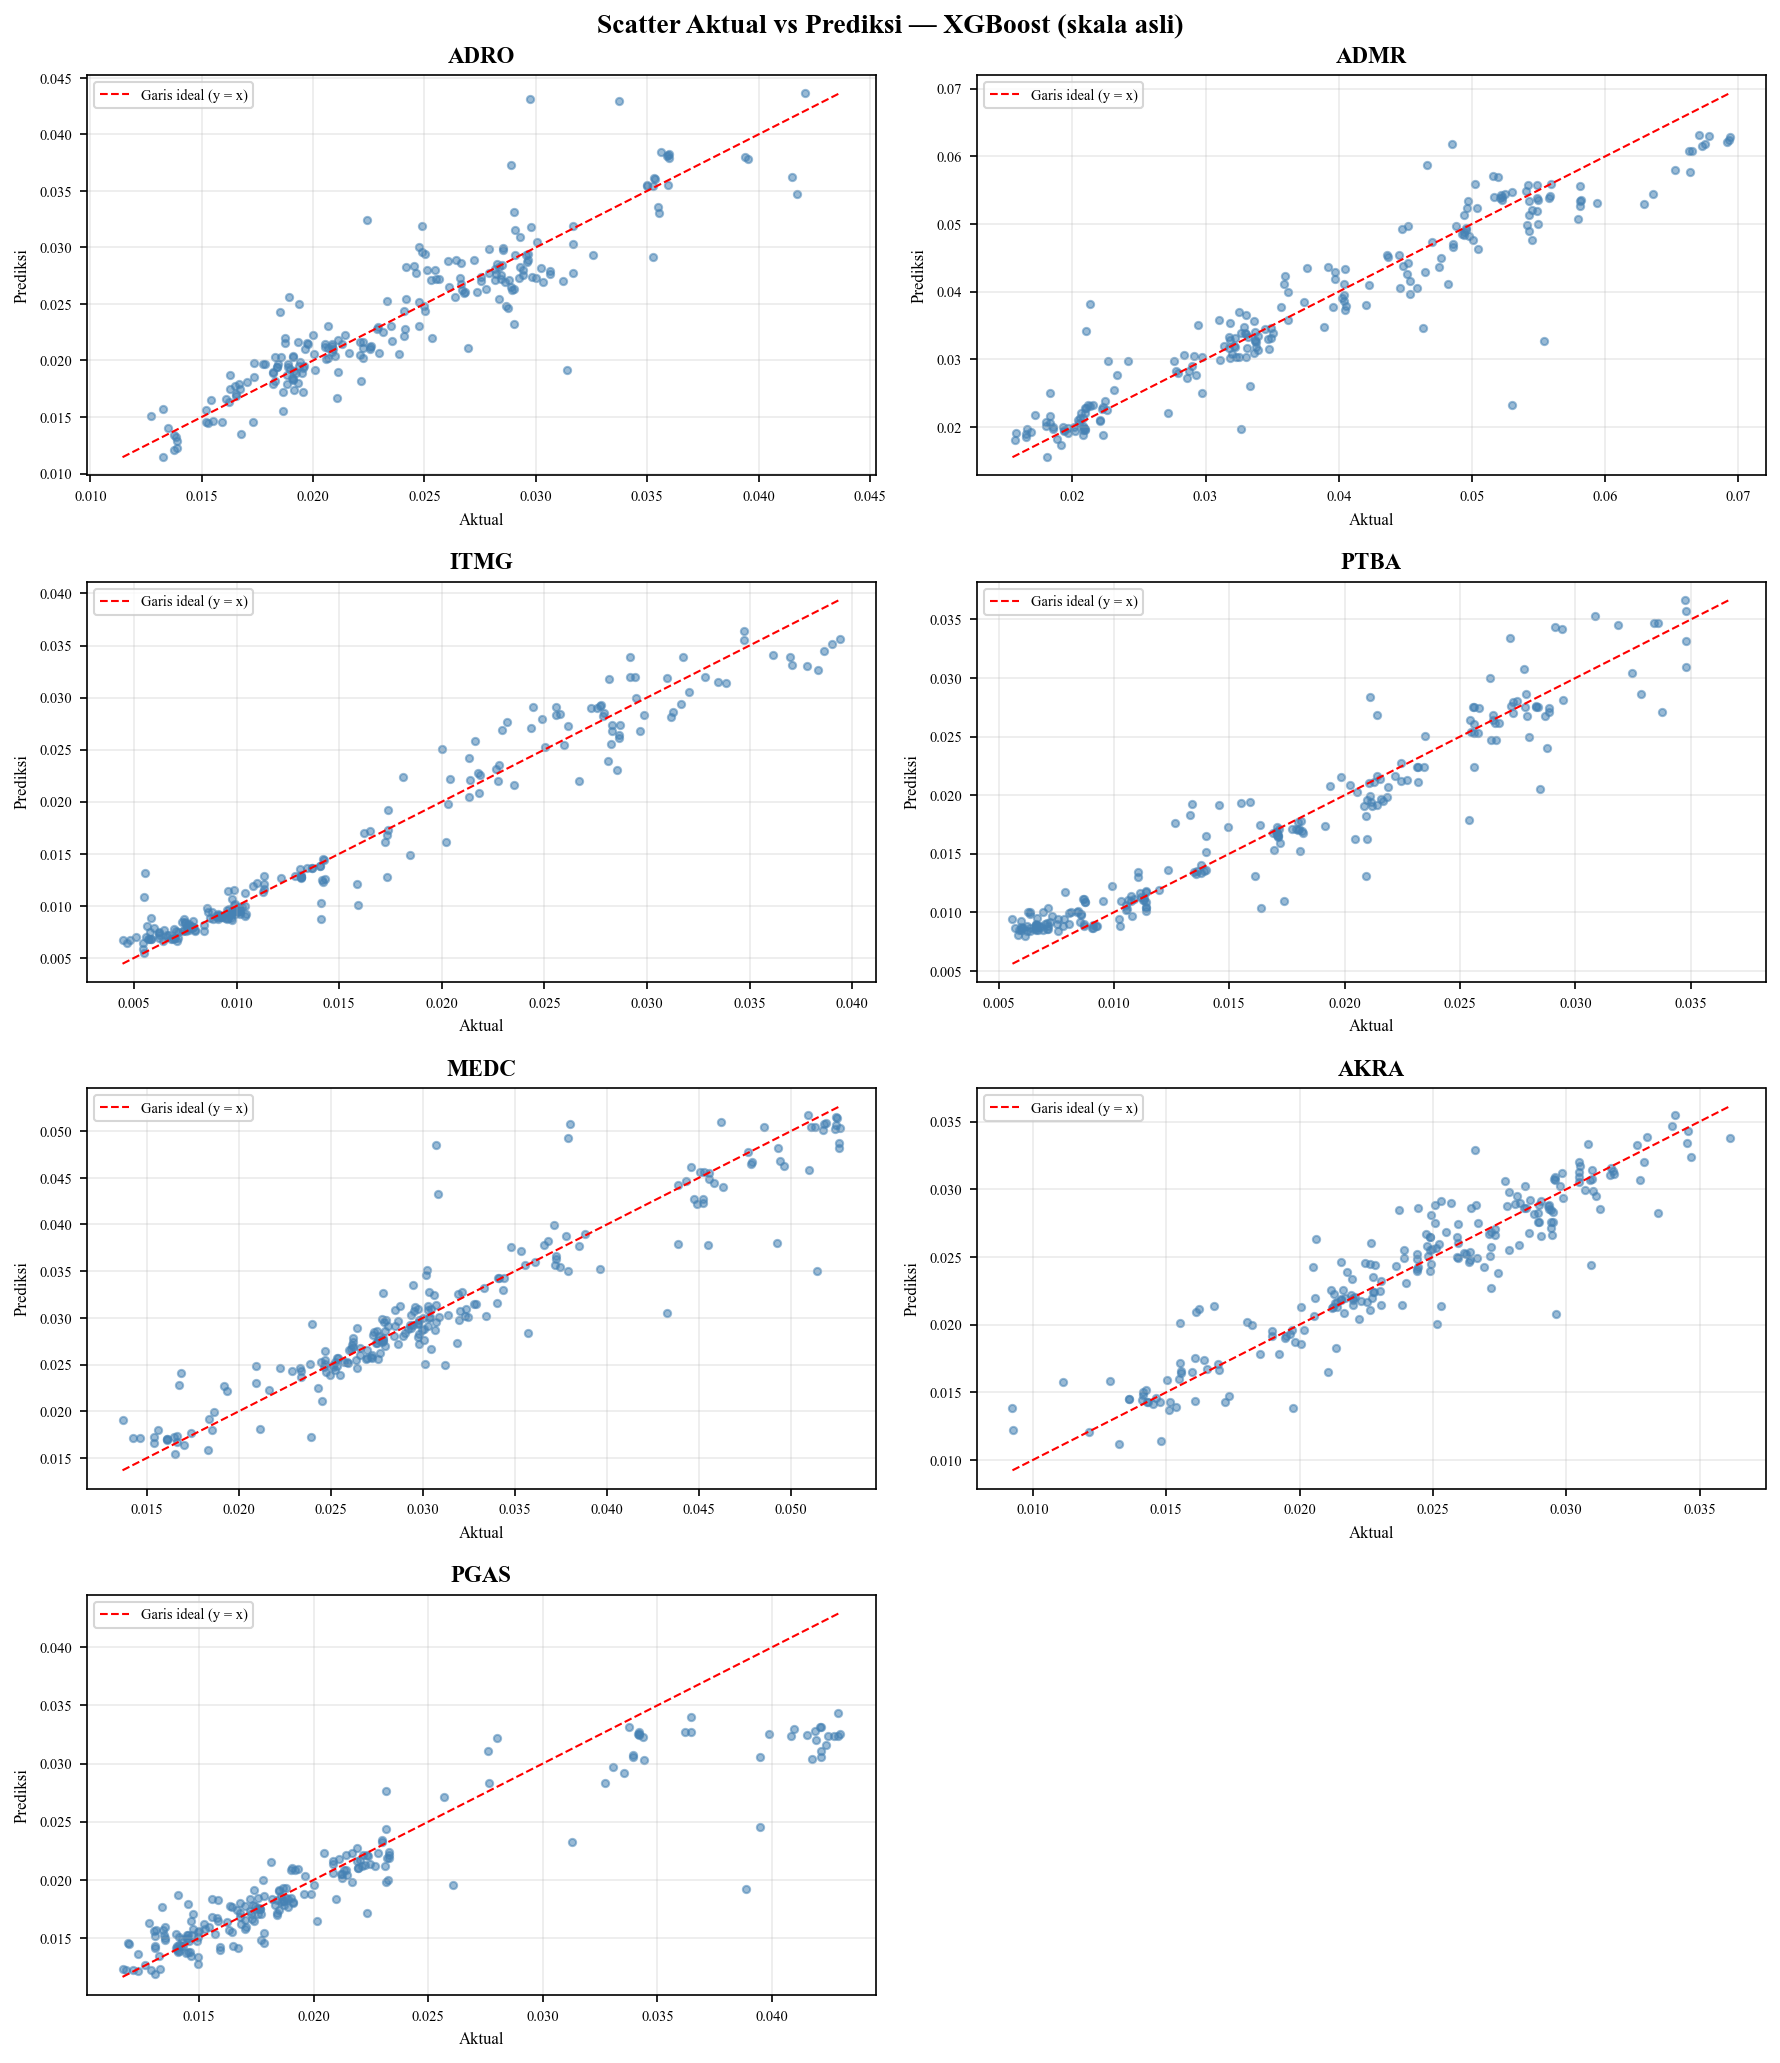

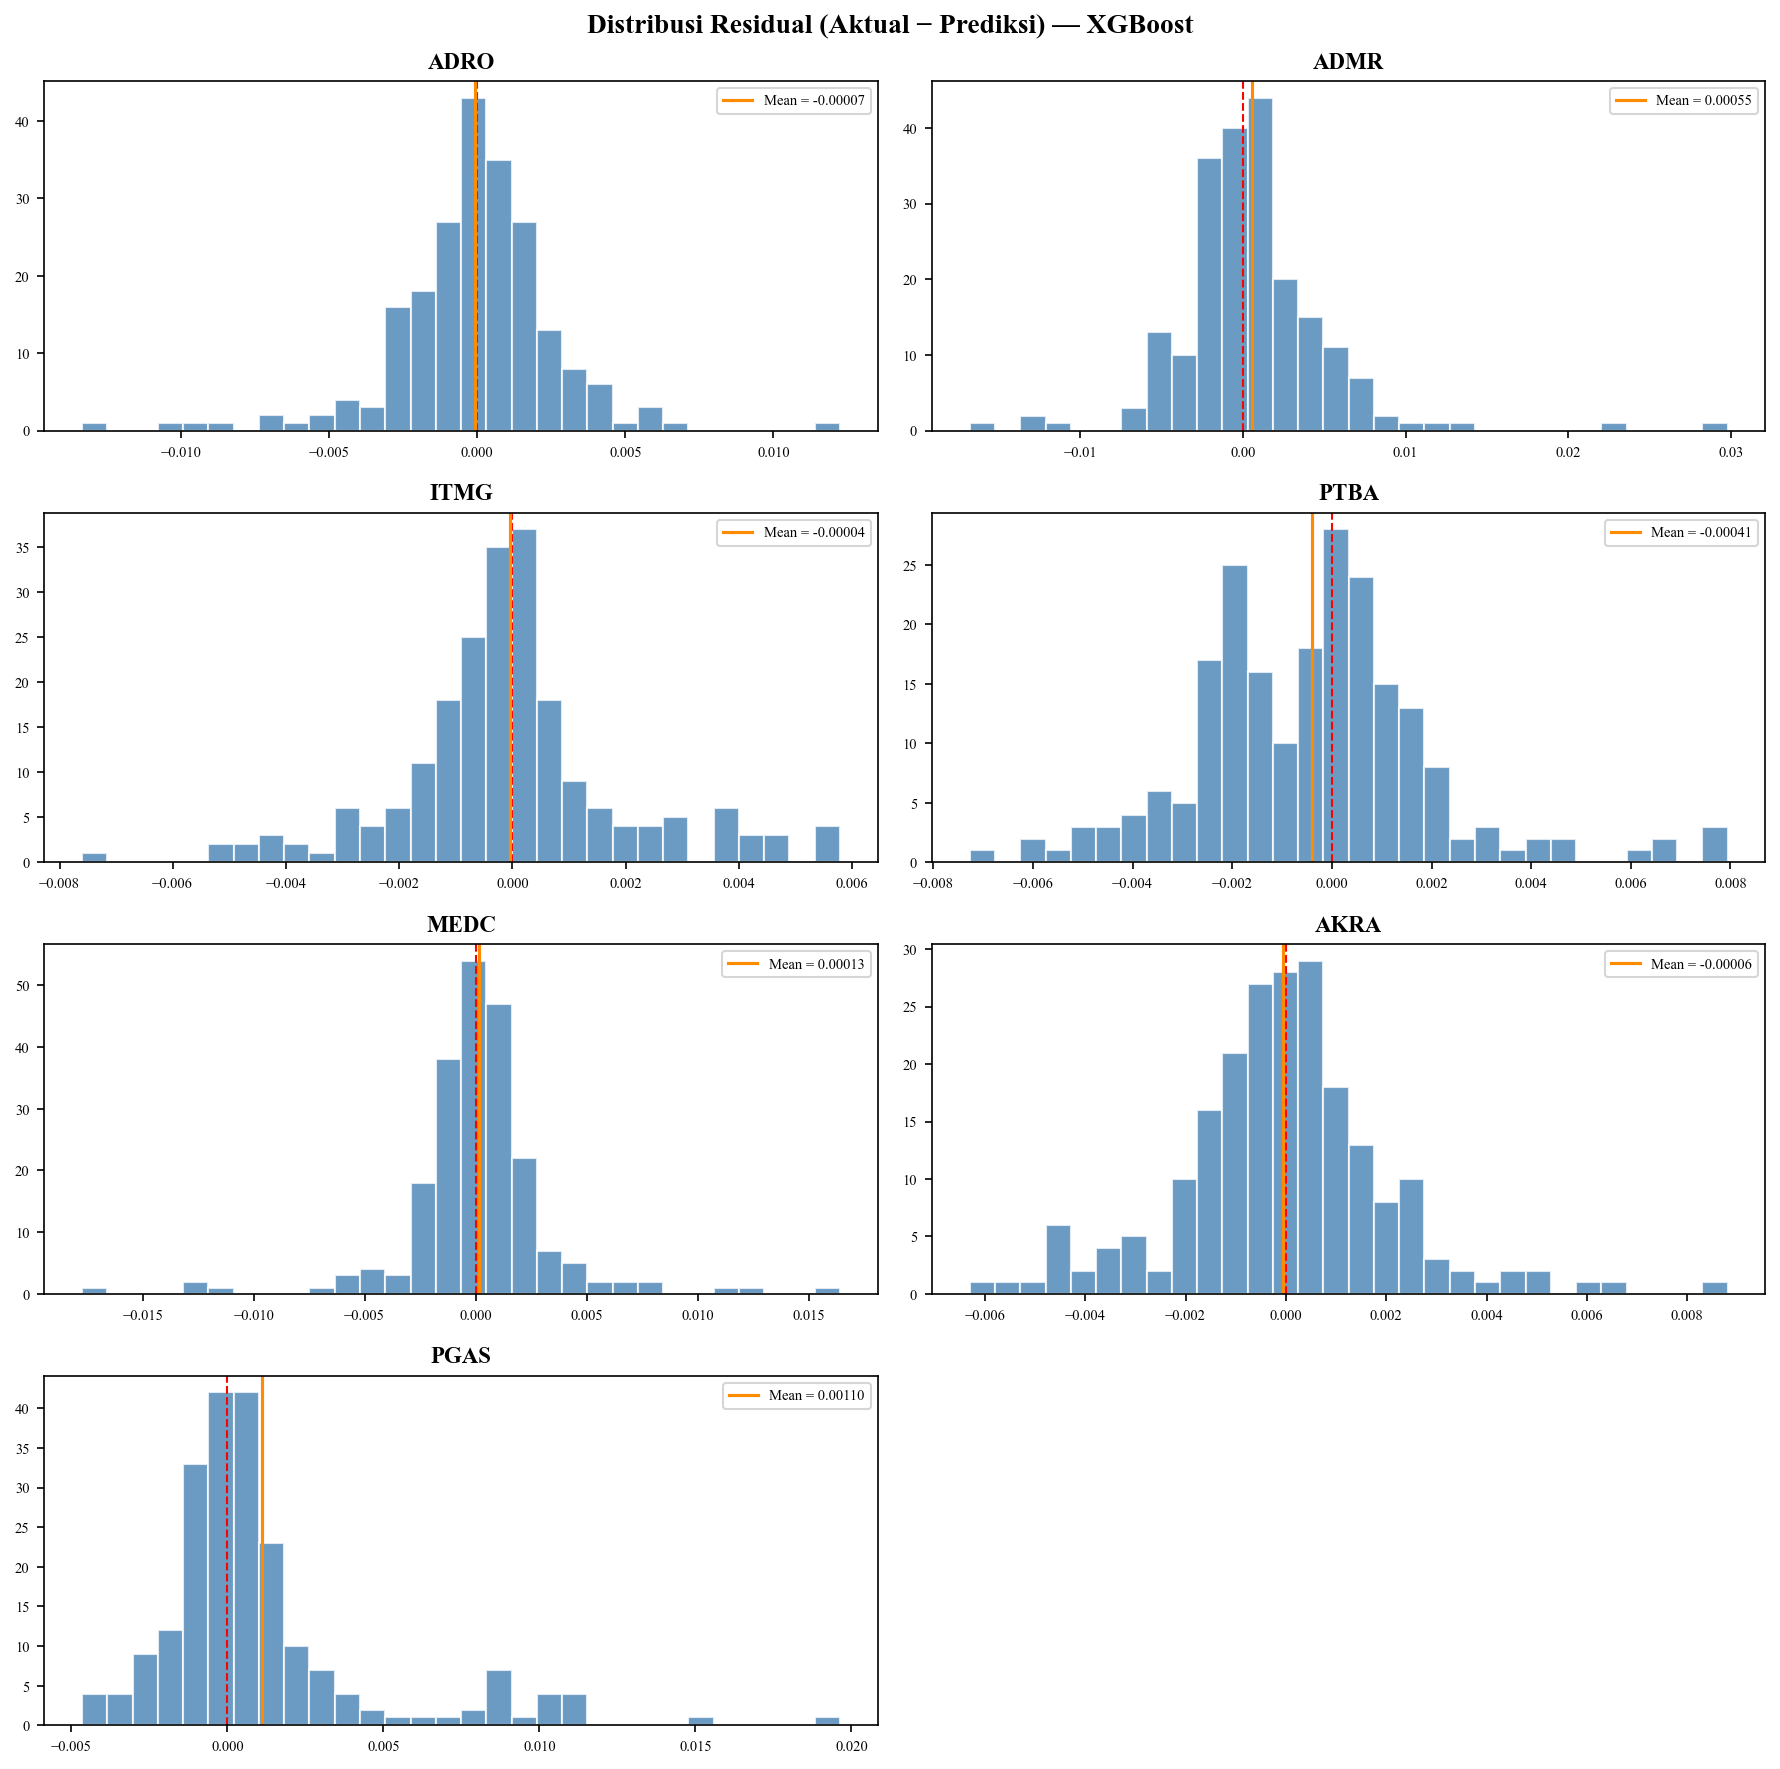

💾 gambar scatter & histogram residual tersimpan


In [16]:
# ============================================================
# CELL 13 — DIAGNOSTIK RESIDUAL PER EMITEN
# ============================================================
# ── (a) Scatter Aktual vs Prediksi ──
ncol = 2; nrow = int(np.ceil(len(emiten_ok) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(12, 3.5 * nrow))
axes = np.array(axes).ravel()

for ax, emiten in zip(axes, emiten_ok):
    d = dict_hasil_xgb[emiten]
    lim = [min(d['Y_Aktual'].min(), d['Y_Prediksi'].min()),
           max(d['Y_Aktual'].max(), d['Y_Prediksi'].max())]
    ax.scatter(d['Y_Aktual'], d['Y_Prediksi'], s=12, alpha=0.55, c='steelblue')
    ax.plot(lim, lim, 'r--', lw=1, label='Garis ideal (y = x)')
    ax.set_title(emiten, fontweight='bold')
    ax.set_xlabel('Aktual', fontsize=8); ax.set_ylabel('Prediksi', fontsize=8)
    ax.legend(fontsize=7); ax.tick_params(labelsize=7); ax.grid(alpha=0.25)

for ax in axes[len(emiten_ok):]:
    ax.axis('off')

plt.suptitle('Scatter Aktual vs Prediksi — XGBoost (skala asli)', fontweight='bold')
plt.tight_layout()
plt.savefig(DIR_GAMBAR / 'gambar_scatter_aktual_prediksi_xgboost.png',
            dpi=150, bbox_inches='tight')
plt.show()

# ── (b) Histogram Residual ──
fig, axes = plt.subplots(nrow, ncol, figsize=(12, 3 * nrow))
axes = np.array(axes).ravel()

for ax, emiten in zip(axes, emiten_ok):
    res = dict_hasil_xgb[emiten]['Residual']
    ax.hist(res, bins=30, color='steelblue', alpha=0.8, edgecolor='white')
    ax.axvline(0, color='red', ls='--', lw=1)
    ax.axvline(res.mean(), color='darkorange', lw=1.5,
               label=f'Mean = {res.mean():.5f}')
    ax.set_title(emiten, fontweight='bold')
    ax.legend(fontsize=7); ax.tick_params(labelsize=7)

for ax in axes[len(emiten_ok):]:
    ax.axis('off')

plt.suptitle('Distribusi Residual (Aktual − Prediksi) — XGBoost', fontweight='bold')
plt.tight_layout()
plt.savefig(DIR_GAMBAR / 'gambar_histogram_residual_xgboost.png',
            dpi=150, bbox_inches='tight')
plt.show()
print('💾 gambar scatter & histogram residual tersimpan')


In [ ]:
import xgboost as xgb

# Saat melatih, sertakan eval_set untuk merekam learning curve
model = xgb.XGBRegressor(
    n_estimators=300,        # sesuaikan dengan hasil tuning Anda
    learning_rate=0.05,
    max_depth=6,
    eval_metric='rmse',      # metrik yang direkam
    # ... hyperparameter lain hasil tuning ...
)

# pastikan eval_set memakai DataFrame sehingga feature names tersimpan
X_tr_df = pd.DataFrame(X_tr, columns=kolom_x) if not isinstance(X_tr, pd.DataFrame) else X_tr
X_te_df = pd.DataFrame(X_te, columns=kolom_x) if not isinstance(X_te, pd.DataFrame) else X_te

model.fit(
    X_tr_df, y_tr,
    eval_set=[(X_tr_df, y_tr), (X_te_df, y_te)],
    verbose=False
)

# Ambil riwayat evaluasi (learning curve)
hasil_eval = model.evals_result()
# hasil_eval['validation_0']['rmse'] → RMSE data latih per pohon
# hasil_eval['validation_1']['rmse'] → RMSE data validasi per pohon

ValueError: data did not contain feature names, but the following fields are expected: Log_Return, Vol_Lag1, Vol_Lag2, Vol_Lag3, Vol_MA5, Vol_STD5, MA5_Ratio, MA10_Ratio, MA20_Ratio, RSI14, Stoch_K, Stoch_D, Volume_ZScore, Sentiment_Mean, Sentiment_Dispersion, News_Count, Ada_Berita

## 💾 CELL 14 — Simpan Hasil Prediksi

In [17]:
df_all = pd.concat(dict_hasil_xgb.values(), ignore_index=True)
df_all.to_csv(DIR_TABEL / 'hasil_prediksi_xgboost.csv', encoding='utf-8-sig', index=False)
print('='*70); print('✅ MODEL XGBOOST SELESAI')
print(f'  Hasil prediksi : hasil_prediksi_xgboost.csv ({len(df_all):,} baris)')
print(f'  Model .pkl     : {DIR_MODEL}')
print('  → Lanjut: jalankan MODEL_lstm_FINAL.ipynb lalu EVALUASI_perbandingan.ipynb')
print('='*70)

✅ MODEL XGBOOST SELESAI
  Hasil prediksi : hasil_prediksi_xgboost.csv (1,500 baris)
  Model .pkl     : e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\04_model\xgboost
  → Lanjut: jalankan MODEL_lstm_FINAL.ipynb lalu EVALUASI_perbandingan.ipynb
